<center><b>MLOps Experimental Learning Assignment 01<br>
End-to-End ML Model Development, CI/CD, and Production Deployment</center></b>
<br>
<center><b>
Course:Machine Learning Operations (MLOps), AIMLCZG523 <br>
Student Name: Harsh Shah <br>
Student ID: 2025af05090 
</center>
---

### Project: Heart Disease Risk Prediction
A reproducible, containerized, and monitored machine learning API that predicts the risk of heart disease from patient health data.

**Dataset:** Heart Disease UCI Dataset (UCI Machine Learning Repository)
**Problem Type:** Binary classification (presence / absence of heart disease)

**Tech Stack:** Python, scikit-learn, MLflow, Pytest, GitHub Actions, Docker, FastAPI, Kubernetes (Minikube), Prometheus, Grafana

## Table of Contents

1. [Project Setup & Environment](#1-project-setup--environment)
2. [Data Acquisition](#2-data-acquisition)
3. [Data Cleaning & Preprocessing](#3-data-cleaning--preprocessing)
4. [Exploratory Data Analysis (EDA)](#4-exploratory-data-analysis-eda)
5. [Feature Engineering & Model Development](#5-feature-engineering--model-development)
6. [Experiment Tracking with MLflow](#6-experiment-tracking-with-mlflow)
7. [Model Packaging & Reproducibility](#7-model-packaging--reproducibility)
8. [CI/CD Pipeline & Automated Testing](#8-cicd-pipeline--automated-testing)
9. [Model Containerization (Docker + FastAPI)](#9-model-containerization-docker--fastapi)
10. [Production Deployment (Kubernetes)](#10-production-deployment-kubernetes)
11. [Monitoring & Logging](#11-monitoring--logging)
12. [Conclusion & Next Steps](#12-conclusion--next-steps)

---

## Project Workflow Overview

| Stage | Marks | Key Tools |
|-------|-------|-----------|
| Data Acquisition & EDA | 5 | pandas, matplotlib, seaborn |
| Feature Engineering & Modelling | 8 | scikit-learn |
| Experiment Tracking | 5 | MLflow |
| Packaging & Reproducibility | 7 | joblib / MLflow, requirements.txt |
| CI/CD & Testing | 8 | Pytest, flake8, GitHub Actions |
| Containerization | 5 | Docker, FastAPI |
| Production Deployment | 7 | Kubernetes (Minikube / Docker Desktop) |
| Monitoring & Logging | 3 | Prometheus, Grafana |
| Documentation & Reporting | 2 | Markdown / PDF report |

**Total: 50 marks**

## 2. Dataset Description and Source

### Dataset: Heart Disease UCI Dataset

The Heart Disease UCI Dataset is a publicly available dataset used for studying and developing machine learning models for heart disease classification.

**Dataset details:**

- **Source:** UCI Machine Learning Repository
- **Problem type:** Binary classification
- **Target variable:** Presence or absence of heart disease
- **Input features:** Patient demographic information and clinical measurements, including age, sex, chest pain type, resting blood pressure, cholesterol, maximum heart rate, and other relevant attributes.
- **Application:** Predicting the presence of heart disease based on patient health attributes.

### Dataset Acquisition

The dataset will be obtained from the UCI Machine Learning Repository. A reproducible data acquisition process will be implemented so that the dataset can be downloaded or retrieved from a documented source during project setup.

### Data Preparation Plan

The following steps will be performed before model development:

1. Inspect the dataset structure, feature names, and data types.
2. Identify missing values, duplicate records, and invalid values.
3. Separate input features from the target variable.
4. Analyze the distribution of numerical and categorical features.
5. Examine the target class distribution.
6. Prepare the data for exploratory data analysis and model development.

The dataset will be split appropriately for model training and evaluation, with preprocessing operations fitted only on the training data to prevent data leakage.

## 3. End-to-End MLOps Workflow

The project follows an end-to-end machine learning lifecycle, covering data preparation, model development, deployment, and production monitoring.

### Workflow Stages

1. **Data Acquisition:** Obtain the Heart Disease UCI Dataset from the documented source.
2. **Exploratory Data Analysis (EDA):** Analyze data quality, feature distributions, correlations, and class balance using visualizations.
3. **Data Preprocessing and Feature Engineering:** Handle missing values, encode categorical variables, scale numerical features where appropriate, and prepare the training and evaluation datasets.
4. **Model Development and Evaluation:** Train at least two classification models, perform cross-validation and hyperparameter tuning, and evaluate performance using accuracy, precision, recall, and ROC-AUC.
5. **Experiment Tracking:** Use MLflow to record experiment parameters, evaluation metrics, plots, and relevant artifacts.
6. **Model Packaging and Reproducibility:** Save the selected model together with its preprocessing pipeline and document the required dependencies.
7. **Automated Testing and CI/CD:** Implement unit tests and configure GitHub Actions to run linting, tests, and model training automatically.
8. **Model Containerization:** Build a Docker image containing the prediction API and its dependencies.
9. **Production Deployment:** Deploy the containerized API to a supported cloud platform or a local Kubernetes environment.
10. **Monitoring and Logging:** Record API requests, expose relevant operational metrics, and demonstrate basic monitoring.
11. **Documentation and Reporting:** Document the implementation, architecture, experiments, testing, deployment, and results.

### Expected Deliverables

The final project will include a GitHub repository, reproducible source code, trained model artifacts, automated tests, a CI/CD workflow, Docker configuration, deployment manifests, monitoring evidence, a 10-page report, deployment access instructions or a public API URL, and a short video demonstrating the overall pipeline.

In [1]:
# Import Essential Libraries
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Visualization configuration
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Project environment initialized successfully.")

Python version: 3.13.5
NumPy version: 2.1.3
Pandas version: 2.2.3
Project environment initialized successfully.


In [2]:
# Create Project Directory Structure

PROJECT_ROOT = Path.cwd() / "heart_disease_mlops"

directories = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "models",
    "mlruns",
    "reports/figures",
    "tests",
    "api",
    "deployment",
    ".github/workflows",
    "logs",
]

for directory in directories:
    (PROJECT_ROOT / directory).mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("\nProject directories created successfully:")

for directory in directories:
    print(f"  {directory}/")


Project root: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops

Project directories created successfully:
  data/raw/
  data/processed/
  notebooks/
  src/
  models/
  mlruns/
  reports/figures/
  tests/
  api/
  deployment/
  .github/workflows/
  logs/


In [3]:
# Configure Project Settings

# Project configuration
PROJECT_NAME = "heart_disease_mlops"
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

# Dataset configuration
DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

# Artifact and reporting paths
MODEL_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
LOG_DIR = PROJECT_ROOT / "logs"

# Ensure reproducibility
np.random.seed(RANDOM_STATE)

# Ensure required directories exist
for path in [
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    MODEL_DIR,
    FIGURES_DIR,
    LOG_DIR,
]:
    path.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_NAME)
print("Random state:", RANDOM_STATE)
print("Test set proportion:", TEST_SIZE)
print("Cross-validation folds:", CV_FOLDS)
print("Raw data directory:", RAW_DATA_DIR.resolve())
print("Processed data directory:", PROCESSED_DATA_DIR.resolve())
print("Model directory:", MODEL_DIR.resolve())
print("\nProject configuration completed successfully.")


Project: heart_disease_mlops
Random state: 42
Test set proportion: 0.2
Cross-validation folds: 5
Raw data directory: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\data\raw
Processed data directory: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\data\processed
Model directory: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\models

Project configuration completed successfully.


In [4]:
# Verify Project Environment and Directory Structure

print("PROJECT ENVIRONMENT CHECK")
print("=" * 40)

# Verify Python and essential library versions
print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# Verify project directories
required_directories = [
    PROJECT_ROOT,
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    MODEL_DIR,
    FIGURES_DIR,
    LOG_DIR,
]

print("\nDirectory Verification:")

for directory in required_directories:
    status = "OK" if directory.exists() else "MISSING"
    print(f"{status}: {directory}")

# Verify directory creation and write access
test_file = LOG_DIR / "environment_check.tmp"

try:
    test_file.write_text("Environment check successful.", encoding="utf-8")
    test_file.unlink()
    print("\nProject directory write access: OK")
except OSError as error:
    print("\nProject directory write access: FAILED")
    print("Error:", error)
    raise

print("\nEnvironment verification completed.")

PROJECT ENVIRONMENT CHECK
Python version: 3.13.5
NumPy version: 2.1.3
Pandas version: 2.2.3

Directory Verification:
OK: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops
OK: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\data\raw
OK: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\data\processed
OK: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\models
OK: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures
OK: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\logs

Project directory write access: OK

Environment verification completed.


In [5]:
# Download the UCI Heart Disease Dataset

from urllib.request import urlopen

# Official UCI Cleveland dataset source
DATASET_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/processed.cleveland.data"
)

RAW_DATA_FILE = RAW_DATA_DIR / "processed.cleveland.data"

# Feature names and original target column
COLUMN_NAMES = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num",
]

try:
    # Download and preserve the original source file
    with urlopen(DATASET_URL, timeout=30) as response:
        dataset_bytes = response.read()

    if not dataset_bytes:
        raise ValueError("The downloaded dataset file is empty.")

    RAW_DATA_FILE.write_bytes(dataset_bytes)

    # Load the downloaded data and interpret '?' as missing
    df = pd.read_csv(
        RAW_DATA_FILE,
        header=None,
        names=COLUMN_NAMES,
        na_values="?",
    )

    if df.empty:
        raise ValueError("The dataset contains no records.")

    if df.shape[1] != len(COLUMN_NAMES):
        raise ValueError("Unexpected number of dataset columns.")

    print("Dataset downloaded successfully.")
    print("Source:", DATASET_URL)
    print("Original file saved to:", RAW_DATA_FILE.resolve())
    print("Dataset shape:", df.shape)
    print("\nFirst five rows:")
    display(df.head())

except Exception as error:
    print("Dataset acquisition failed.")
    print("Error:", error)
    raise

Dataset downloaded successfully.
Source: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
Original file saved to: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\data\raw\processed.cleveland.data
Dataset shape: (303, 14)

First five rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
# Inspect Dataset Structure and Data Types

print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nData types of all columns:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nDataset dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Data types of all columns:


,Data Type
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64



Dataset dimensions:
Rows: 303
Columns: 14

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage (%),Data Type
ca,4,1.32,float64
thal,2,0.66,float64
cp,0,0.00,float64
trestbps,0,0.00,float64
age,0,0.00,float64
sex,0,0.00,float64
fbs,0,0.00,float64
chol,0,0.00,float64
restecg,0,0.00,float64
thalach,0,0.00,float64



Total missing values: 6
Columns with missing values: 2
Total dataset records: 303


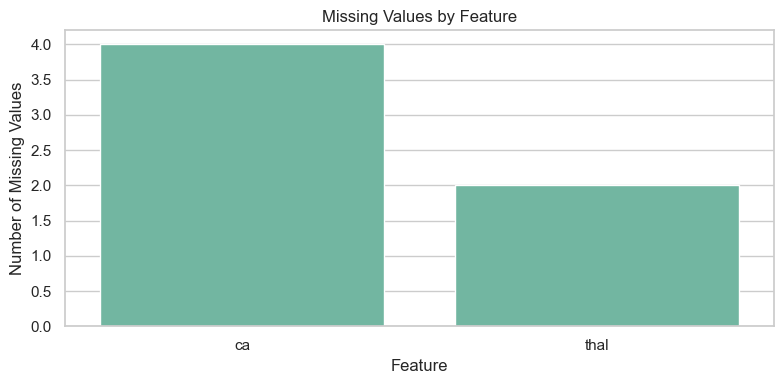

In [7]:
# Analyze Missing Values

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str),
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False,
)

print("MISSING VALUE ANALYSIS")
print("=" * 50)

display(missing_summary)

print(f"\nTotal missing values: {df.isnull().sum().sum()}")
print(f"Columns with missing values: {(df.isnull().sum() > 0).sum()}")
print(f"Total dataset records: {len(df)}")

# Visualize missing values
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if not missing_counts.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(
        x=missing_counts.index,
        y=missing_counts.values,
    )
    plt.title("Missing Values by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Number of Missing Values")
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "missing_values.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
else:
    print("No missing values found.")


In [8]:
# Check Duplicate Records

duplicate_count = df.duplicated().sum()

print("DUPLICATE RECORD ANALYSIS")
print("=" * 50)
print("Total records:", len(df))
print("Duplicate records:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

if duplicate_count > 0:
    print("\nDuplicate records identified:")
    display(df[df.duplicated(keep=False)].sort_values(by=COLUMN_NAMES))
else:
    print("\nNo duplicate records found.")

print("\nOriginal dataset remains unchanged.")


DUPLICATE RECORD ANALYSIS
Total records: 303
Duplicate records: 0
Duplicate percentage: 0.0 %

No duplicate records found.

Original dataset remains unchanged.


ORIGINAL TARGET DISTRIBUTION


,Count,Percentage (%)
num,,
0,164,54.13
1,55,18.15
2,36,11.88
3,35,11.55
4,13,4.29


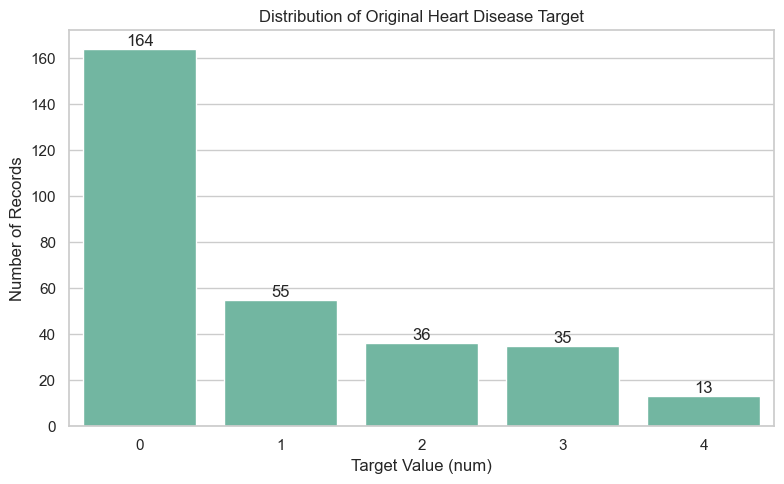

In [9]:
# Analyze Original Target Distribution

target_counts = df["num"].value_counts().sort_index()

print("ORIGINAL TARGET DISTRIBUTION")
print("=" * 50)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": (target_counts / len(df) * 100).round(2),
})

display(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="num",
    order=sorted(df["num"].unique()),
)

ax.bar_label(ax.containers[0])

plt.title("Distribution of Original Heart Disease Target")
plt.xlabel("Target Value (num)")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "original_target_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [10]:
# Create Binary Target Variable

# Create a separate working copy; preserve the original dataset
df_model = df.copy()

# Convert the original target into binary classification:
# 0 = No heart disease
# 1 = Heart disease present
df_model["target"] = (df_model["num"] > 0).astype(int)

# Remove the original multi-class target from model features
df_model.drop(columns=["num"], inplace=True)

print("BINARY TARGET CREATED")
print("=" * 50)

print("Working dataset shape:", df_model.shape)
print("\nBinary target distribution:")

binary_counts = df_model["target"].value_counts().sort_index()

binary_summary = pd.DataFrame({
    "Class": ["No heart disease", "Heart disease present"],
    "Count": [
        binary_counts.get(0, 0),
        binary_counts.get(1, 0),
    ],
    "Percentage (%)": [
        round(binary_counts.get(0, 0) / len(df_model) * 100, 2),
        round(binary_counts.get(1, 0) / len(df_model) * 100, 2),
    ],
})

display(binary_summary)

print("Original dataset shape:", df.shape)
print("Original target preserved:", "num" in df.columns)

assert df_model.shape == (303, 14)
assert df_model["target"].nunique() == 2
assert df_model["target"].isnull().sum() == 0

print("\nBinary target validation passed.")

BINARY TARGET CREATED
Working dataset shape: (303, 14)

Binary target distribution:


,Class,Count,Percentage (%)
0,No heart disease,164,54.13
1,Heart disease present,139,45.87


Original dataset shape: (303, 14)
Original target preserved: True

Binary target validation passed.


In [11]:
# Identify Numerical and Categorical Features

# Continuous numerical measurements
NUMERICAL_FEATURES = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
]

# Categorical or discrete coded clinical features
CATEGORICAL_FEATURES = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal",
]

TARGET_COLUMN = "target"

# Validate feature definitions
ALL_FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

assert len(ALL_FEATURES) == 13
assert len(set(ALL_FEATURES)) == 13
assert set(ALL_FEATURES) == set(df_model.columns) - {TARGET_COLUMN}

print("FEATURE CONFIGURATION")
print("=" * 50)

print(f"\nNumerical features ({len(NUMERICAL_FEATURES)}):")
print(NUMERICAL_FEATURES)

print(f"\nCategorical features ({len(CATEGORICAL_FEATURES)}):")
print(CATEGORICAL_FEATURES)

print(f"\nTarget column: {TARGET_COLUMN}")
print("Total input features:", len(ALL_FEATURES))

print("\nFeature configuration validation passed.")

FEATURE CONFIGURATION

Numerical features (5):
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features (8):
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Target column: target
Total input features: 13

Feature configuration validation passed.


In [12]:
# Descriptive Statistical Analysis

print("DESCRIPTIVE STATISTICS — NUMERICAL FEATURES")
print("=" * 60)

display(df_model[NUMERICAL_FEATURES].describe().round(2))

print("\nDESCRIPTIVE STATISTICS — CATEGORICAL FEATURES")
print("=" * 60)

display(df_model[CATEGORICAL_FEATURES].describe().round(2))

print("\nTARGET DISTRIBUTION")
print("=" * 60)

display(
    df_model[TARGET_COLUMN]
    .value_counts()
    .sort_index()
    .rename_axis("Target")
    .to_frame("Count")
)

DESCRIPTIVE STATISTICS — NUMERICAL FEATURES


,age,trestbps,chol,thalach,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20



DESCRIPTIVE STATISTICS — CATEGORICAL FEATURES


,sex,cp,fbs,restecg,exang,slope,ca,thal
count,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00
mean,0.68,3.16,0.15,0.99,0.33,1.60,0.67,4.73
std,0.47,0.96,0.36,0.99,0.47,0.62,0.94,1.94
min,0.00,1.00,0.00,0.00,0.00,1.00,0.00,3.00
25%,0.00,3.00,0.00,0.00,0.00,1.00,0.00,3.00
50%,1.00,3.00,0.00,1.00,0.00,2.00,0.00,3.00
75%,1.00,4.00,0.00,2.00,1.00,2.00,1.00,7.00
max,1.00,4.00,1.00,2.00,1.00,3.00,3.00,7.00



TARGET DISTRIBUTION


,Count
Target,
0,164
1,139


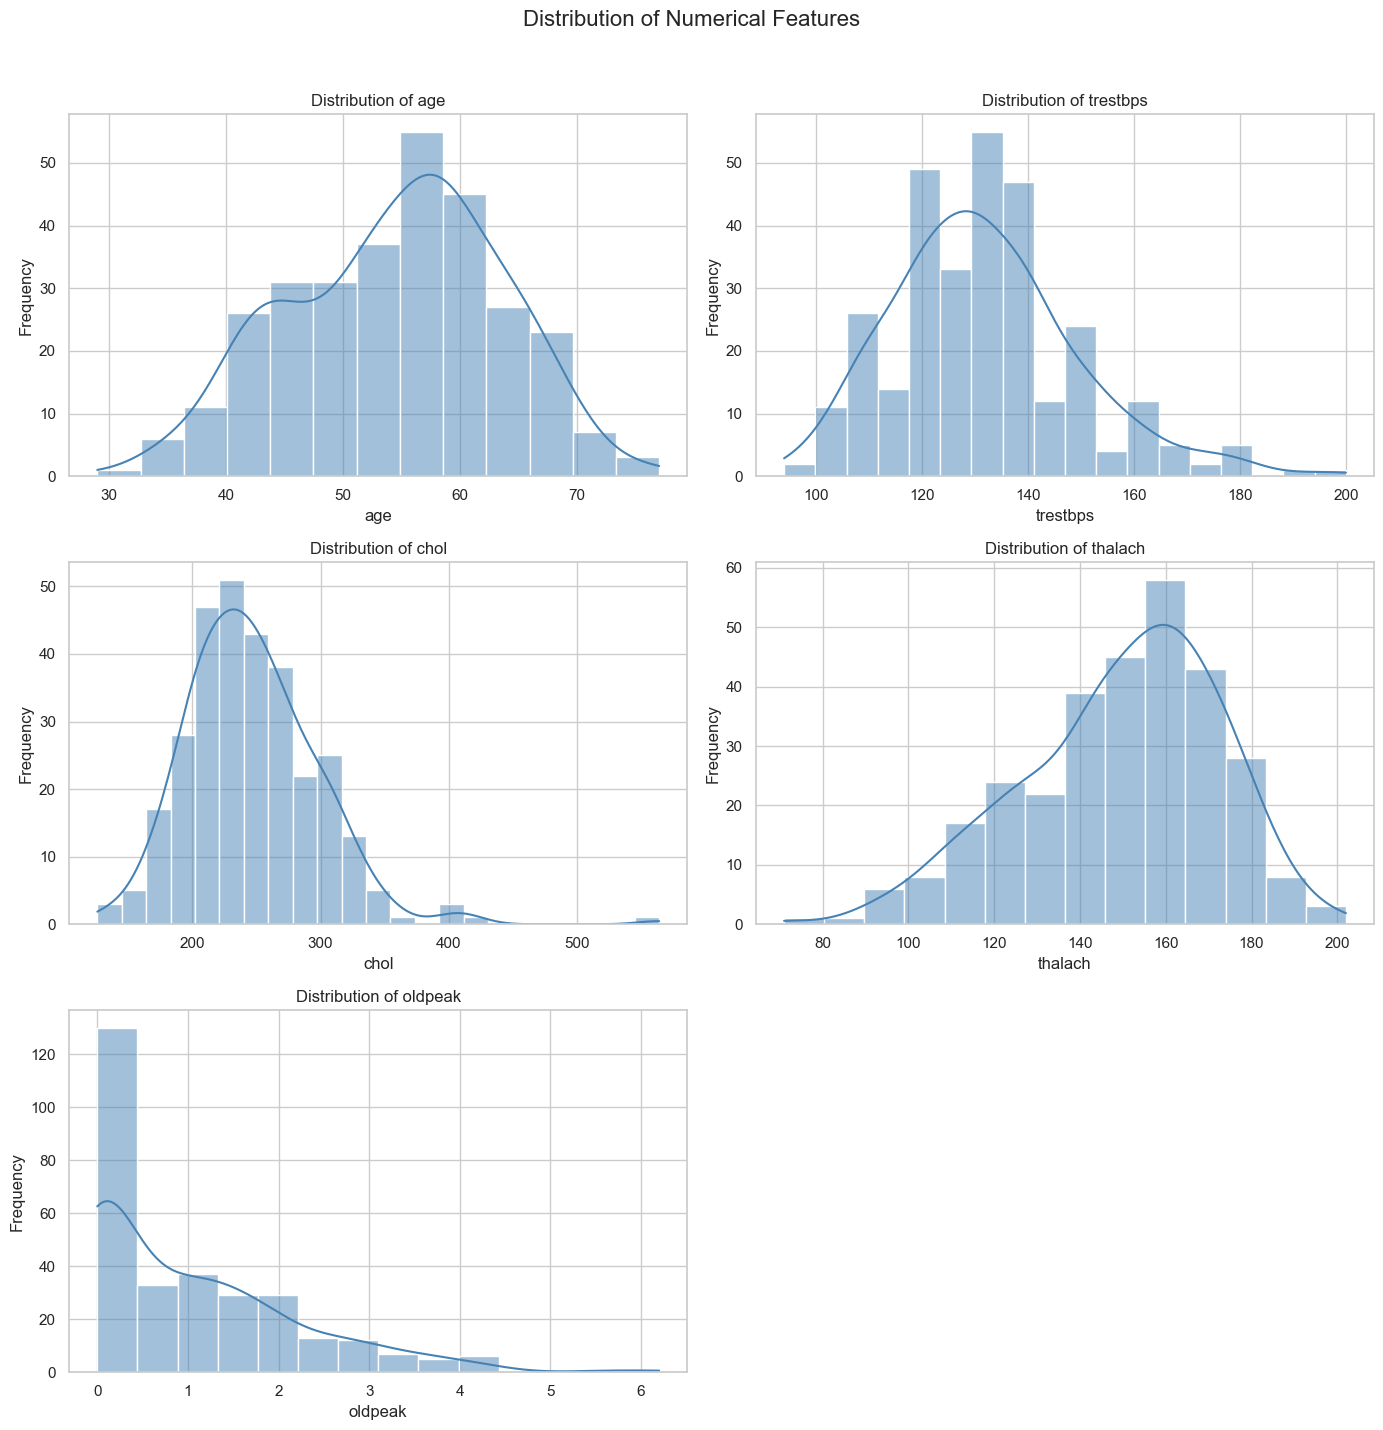

In [13]:

# Numerical Feature Distribution Plots

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 14),
)

axes = axes.flatten()

for i, feature in enumerate(NUMERICAL_FEATURES):
    sns.histplot(
        data=df_model,
        x=feature,
        kde=True,
        ax=axes[i],
        color="steelblue",
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

# Hide the unused sixth subplot
axes[-1].set_visible(False)

fig.suptitle(
    "Distribution of Numerical Features",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "numerical_feature_distributions.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

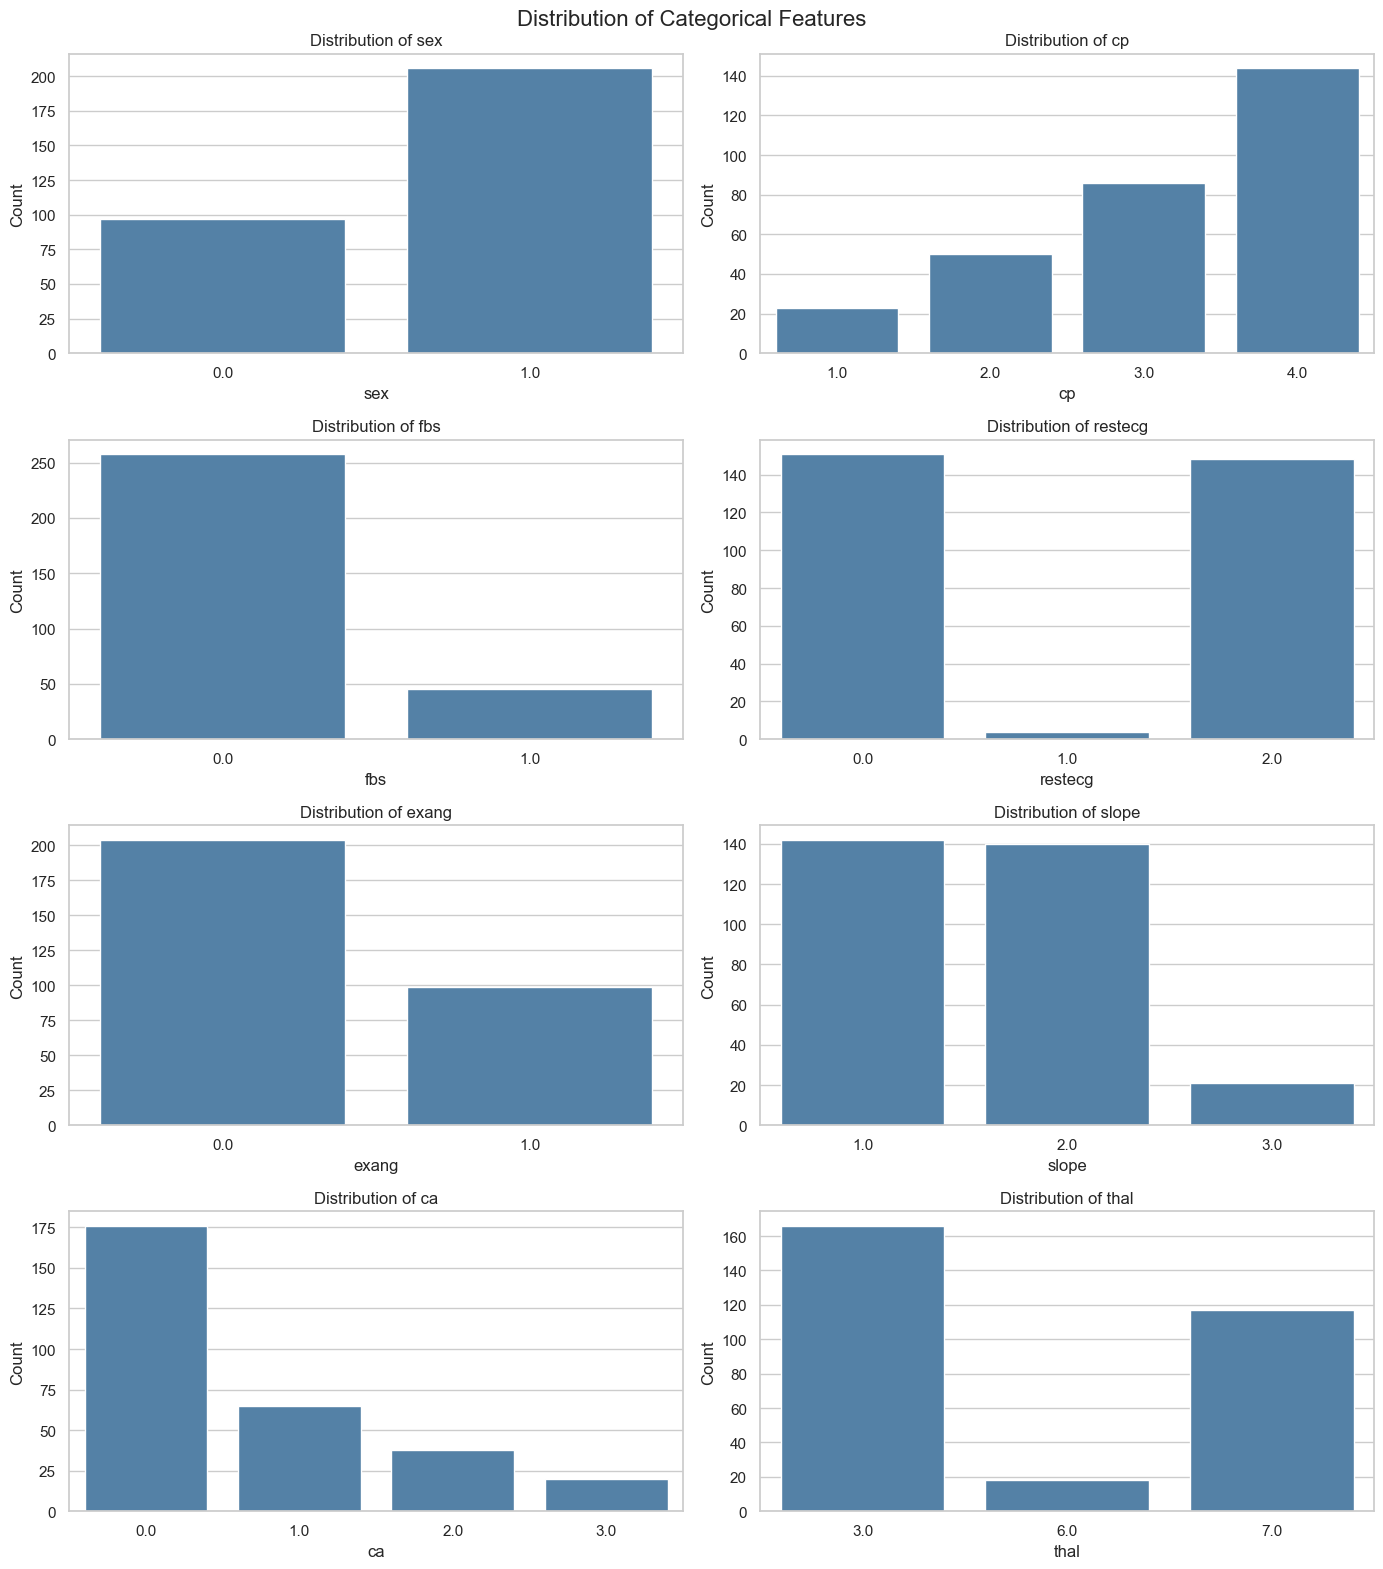

Categorical feature distribution plots generated and saved.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures


In [14]:
# Categorical Feature Distribution Plots

n_features = len(CATEGORICAL_FEATURES)
n_cols = 2
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(14, 4 * n_rows),
)

axes = axes.flatten()

for i, feature in enumerate(CATEGORICAL_FEATURES):
    sns.countplot(
        data=df_model,
        x=feature,
        ax=axes[i],
        color="steelblue",
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Count")

    axes[i].tick_params(axis="x", rotation=0)

# Hide any unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Distribution of Categorical Features",
    fontsize=16,
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "categorical_feature_distributions.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Categorical feature distribution plots generated and saved.")
print("Location:", FIGURES_DIR.resolve())


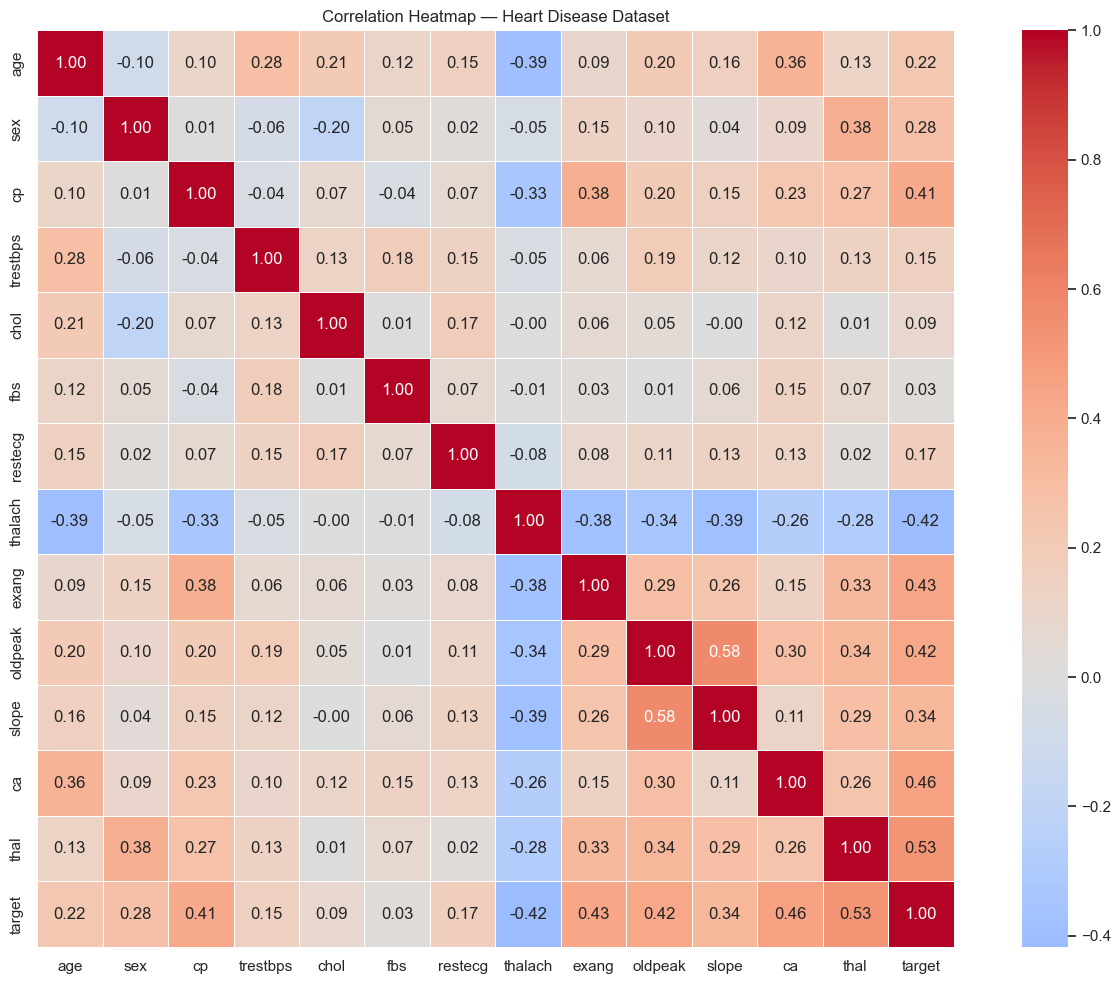

FEATURE CORRELATIONS WITH BINARY TARGET


,Correlation with Target
thal,0.525689
ca,0.460442
exang,0.431894
oldpeak,0.424510
thalach,-0.417167
cp,0.414446
slope,0.339213
sex,0.276816
age,0.223120
restecg,0.169202



Correlation heatmap generated and saved.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures


In [15]:
# Correlation Analysis and Heatmap

# Calculate correlations for an exploratory overview
correlation_matrix = df_model.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
)

plt.title("Correlation Heatmap — Heart Disease Dataset")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Display correlations with the binary target
target_correlations = (
    correlation_matrix[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values(key=abs, ascending=False)
)

print("FEATURE CORRELATIONS WITH BINARY TARGET")
print("=" * 50)

display(target_correlations.to_frame(name="Correlation with Target"))

print("\nCorrelation heatmap generated and saved.")
print("Location:", FIGURES_DIR.resolve())

## Exploratory Data Analysis (EDA)

This section explores the Heart Disease UCI dataset to understand its structure, data quality, feature distributions, and relationships with the target variable.

The analysis includes missing-value assessment, duplicate detection, target distribution, descriptive statistics, feature visualizations, and correlation analysis. These findings will help guide feature preprocessing and model development.

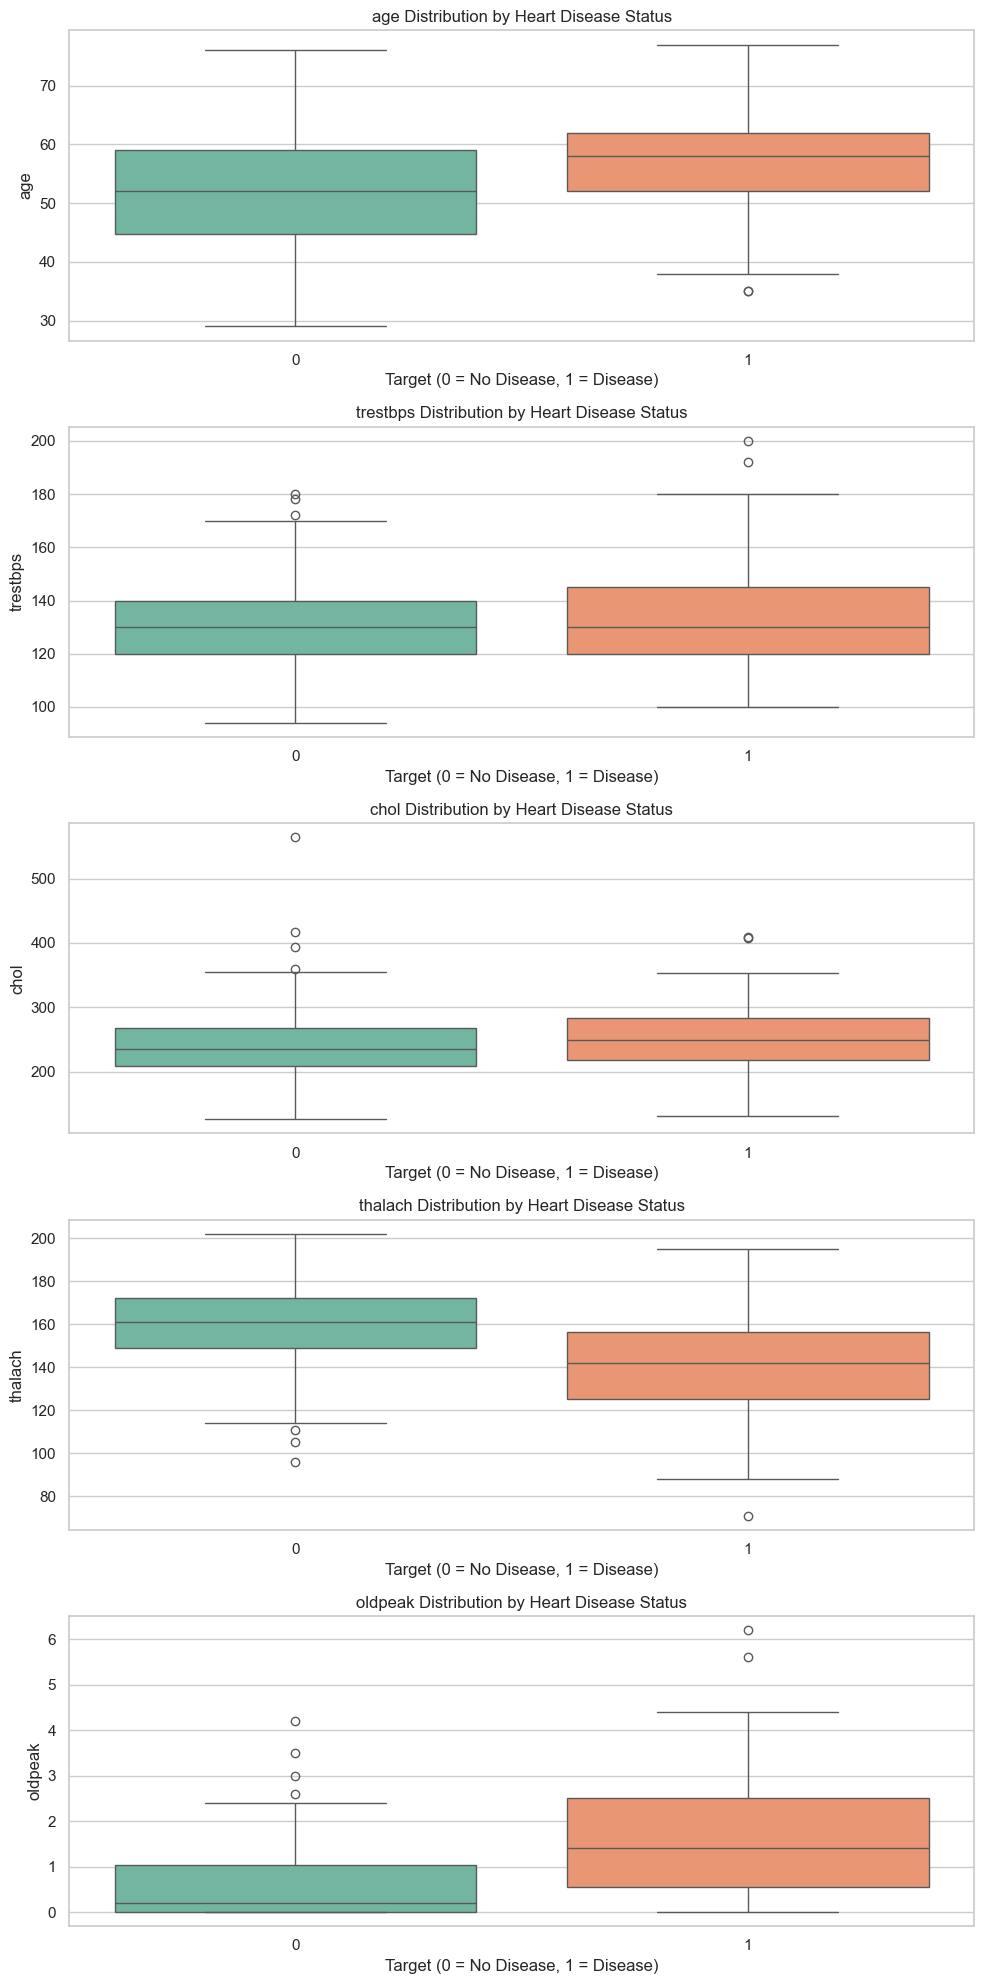

Numerical feature comparison plots generated and saved.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures\numerical_features_by_target.png


In [16]:
# Numerical Feature Comparison by Target Class

fig, axes = plt.subplots(
    nrows=len(NUMERICAL_FEATURES),
    ncols=1,
    figsize=(10, 4 * len(NUMERICAL_FEATURES))
)

for ax, feature in zip(axes, NUMERICAL_FEATURES):
    sns.boxplot(
        data=df_model,
        x=TARGET_COLUMN,
        y=feature,
        hue=TARGET_COLUMN,
        legend=False,
        ax=ax
    )
    ax.set_title(f"{feature} Distribution by Heart Disease Status")
    ax.set_xlabel("Target (0 = No Disease, 1 = Disease)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "numerical_features_by_target.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Numerical feature comparison plots generated and saved.")
print("Location:", (FIGURES_DIR / "numerical_features_by_target.png").resolve())

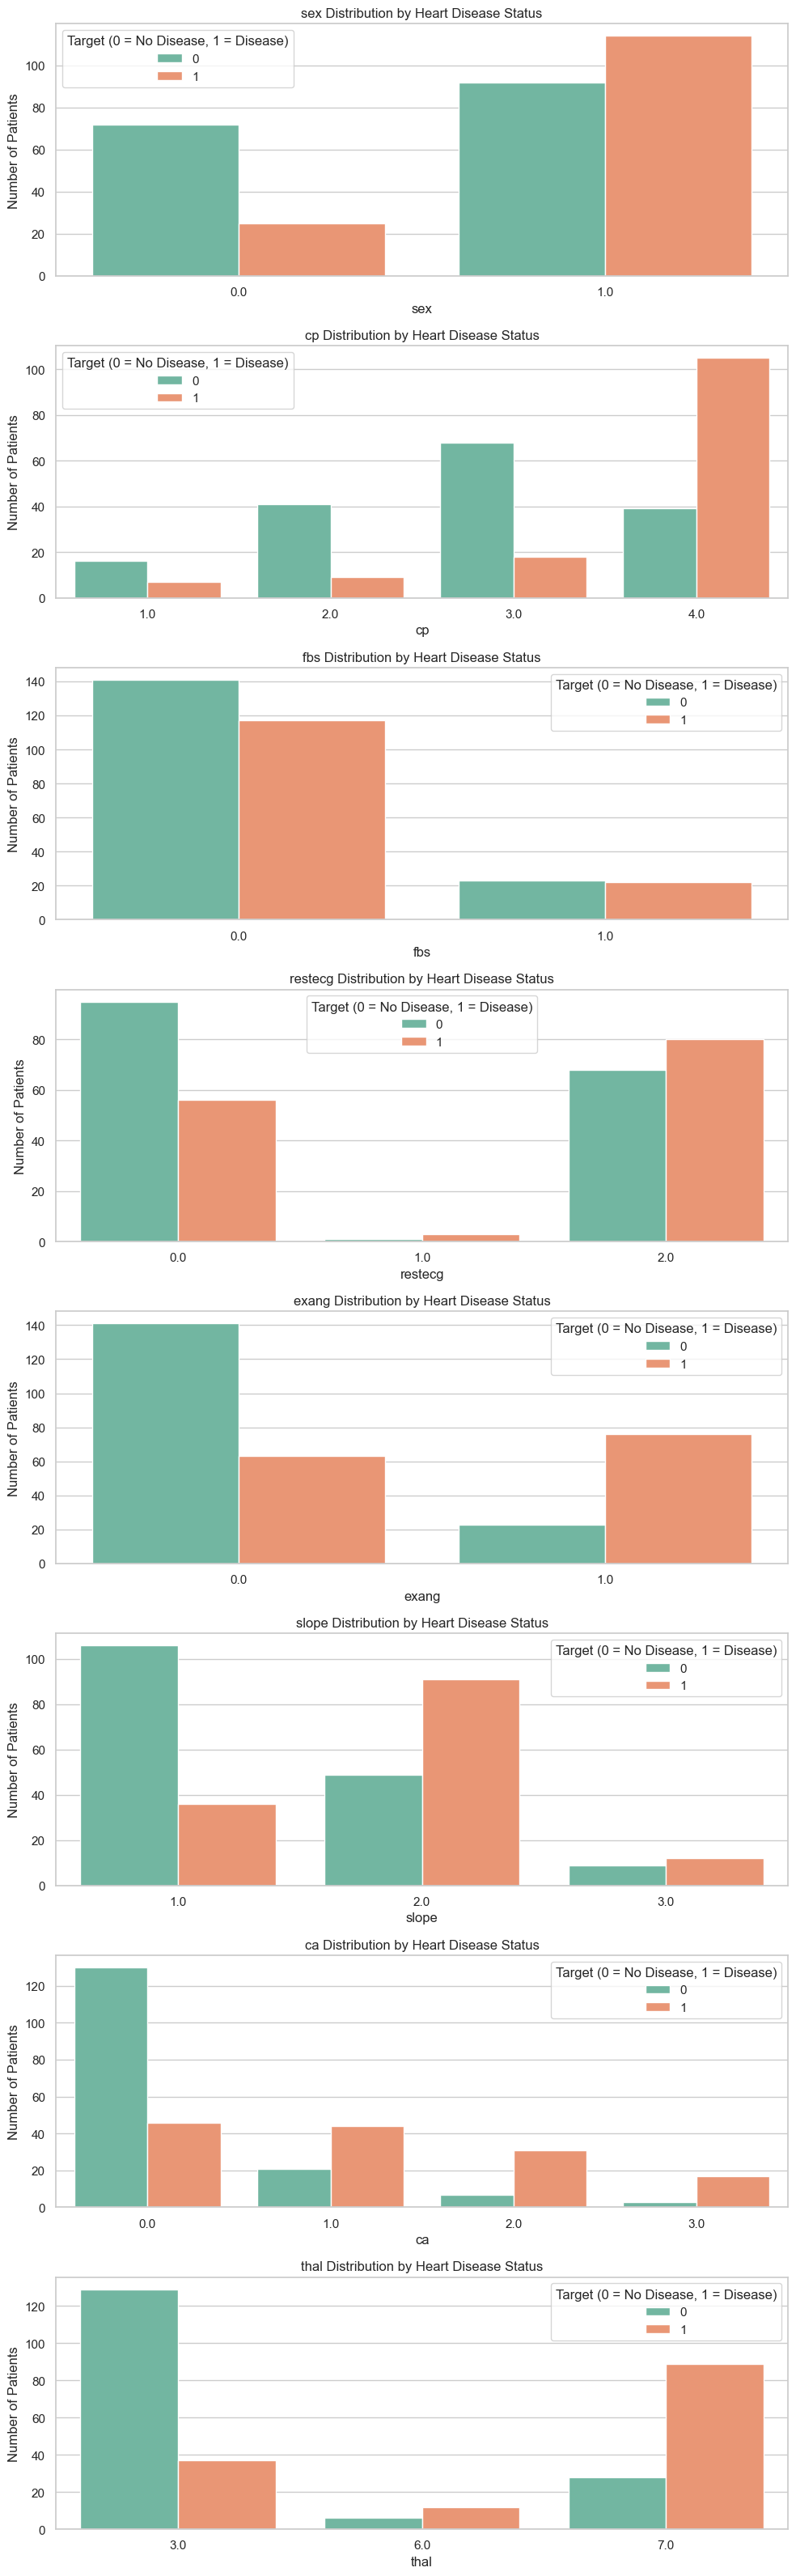

Categorical feature comparison plots generated and saved.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures\categorical_features_by_target.png


In [17]:
# Categorical Feature Comparison by Target Class

fig, axes = plt.subplots(
    nrows=len(CATEGORICAL_FEATURES),
    ncols=1,
    figsize=(10, 4 * len(CATEGORICAL_FEATURES))
)

for ax, feature in zip(axes, CATEGORICAL_FEATURES):
    sns.countplot(
        data=df_model,
        x=feature,
        hue=TARGET_COLUMN,
        ax=ax
    )
    ax.set_title(f"{feature} Distribution by Heart Disease Status")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Patients")
    ax.legend(title="Target (0 = No Disease, 1 = Disease)")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "categorical_features_by_target.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Categorical feature comparison plots generated and saved.")
print("Location:", (FIGURES_DIR / "categorical_features_by_target.png").resolve())

### EDA Summary and Key Observations

The exploratory data analysis provided an overview of the dataset's quality, distributions, and relationships with the target variable.

Key observations:

- **Dataset size:** 303 patient records and 13 input features.
- **Missing values:** Six missing entries were identified across the `ca` and `thal` features.
- **Duplicate records:** No duplicate records were found.
- **Target distribution:** 164 patients (54.13%) belong to class 0, while 139 patients (45.87%) belong to class 1.
- **Feature distributions:** Numerical and categorical visualizations were generated to examine feature patterns and potential outliers.
- **Feature relationships:** Correlation analysis and target-based comparisons were performed to explore potential relationships with heart disease.

### Conclusion

The dataset is suitable for proceeding to feature preprocessing and model development, provided that missing values are handled appropriately. Preprocessing transformations will be fitted on the training data only to prevent data leakage. The train-test split will preserve the target class proportions.

In [18]:
# Train-Test Split

from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df_model[ALL_FEATURES].copy()
y = df_model[TARGET_COLUMN].copy()

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# Verify the split
print("TRAIN-TEST SPLIT SUMMARY")
print("=" * 45)
print("Total records:", len(df_model))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of input features:", X_train.shape[1])

print("\nTraining target distribution:")
display(
    y_train.value_counts()
    .sort_index()
    .rename(index={0: "No Heart Disease", 1: "Heart Disease"})
    .to_frame(name="Count")
)

print("\nTesting target distribution:")
display(
    y_test.value_counts()
    .sort_index()
    .rename(index={0: "No Heart Disease", 1: "Heart Disease"})
    .to_frame(name="Count")
)

assert len(X_train) + len(X_test) == len(df_model)
assert X_train.shape[1] == len(ALL_FEATURES)
assert X_train.index.intersection(X_test.index).empty

print("\nTrain-test split completed successfully.")

TRAIN-TEST SPLIT SUMMARY
Total records: 303
Training records: 242
Testing records: 61
Number of input features: 13

Training target distribution:


,Count
target,
No Heart Disease,131
Heart Disease,111



Testing target distribution:


,Count
target,
No Heart Disease,33
Heart Disease,28



Train-test split completed successfully.


## Feature Preprocessing and Model Development

### Feature Preprocessing Strategy

The dataset contains numerical features, categorical features, and missing values. Appropriate preprocessing is required before training machine learning models.

**Numerical features**
- Impute missing values using the median.
- Apply standard scaling to bring features onto a comparable scale.

**Categorical features**
- Impute missing values using the most frequent value.
- Apply one-hot encoding to represent categorical values numerically.

### Preventing Data Leakage

All preprocessing transformations will be implemented using a Scikit-learn pipeline and fitted only on the training data. The fitted transformations will then be applied to the test data without refitting.

This approach ensures that information from the test set does not influence preprocessing or model training and supports reproducible evaluation.

In [19]:
# Feature Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical feature preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical feature preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, NUMERICAL_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)

# Verify the configuration
print("Preprocessing pipeline configured successfully.")
print("\nNumerical features:", NUMERICAL_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)
print("\nNumerical preprocessing: Median Imputation -> Standard Scaling")
print("Categorical preprocessing: Most-Frequent Imputation -> One-Hot Encoding")
print("\nPipeline will be fitted on training data only.")

Preprocessing pipeline configured successfully.

Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Numerical preprocessing: Median Imputation -> Standard Scaling
Categorical preprocessing: Most-Frequent Imputation -> One-Hot Encoding

Pipeline will be fitted on training data only.


### Model Selection and Training Strategy

Two classification algorithms will be evaluated for predicting the presence of heart disease.

**1. Logistic Regression**
- A linear classification model that estimates the probability of a patient having heart disease.
- Provides a useful baseline and supports interpretation of feature relationships.
- Benefits from standardized numerical features.

**2. Random Forest Classifier**
- An ensemble model that combines predictions from multiple decision trees.
- Can capture nonlinear relationships and interactions between features.
- Does not require numerical feature scaling, but will use the same preprocessing framework for consistent evaluation.

### Evaluation Strategy

Both models will use the same training and testing split and preprocessing pipeline. Five-fold stratified cross-validation will be used on the training set for model comparison.

Evaluation will include accuracy, precision, recall, F1-score, and ROC-AUC. Since this is a medical prediction task, recall and ROC-AUC will also be considered rather than relying on accuracy alone.

The test set will be reserved for final evaluation after model selection.

In [20]:
# Configure Classification Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define classification models with preprocessing
logistic_regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Store models for consistent evaluation
models = {
    "Logistic Regression": logistic_regression_pipeline,
    "Random Forest": random_forest_pipeline
}

# Configure stratified five-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Classification pipelines configured successfully.")
print("Models:", list(models.keys()))
print("Cross-validation folds:", CV_FOLDS)
print("Evaluation metrics:", list(scoring_metrics.keys()))
print("\nNo model has been fitted yet.")

Classification pipelines configured successfully.
Models: ['Logistic Regression', 'Random Forest']
Cross-validation folds: 5
Evaluation metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

No model has been fitted yet.


In [21]:
# Cross-Validation Model Evaluation

cv_results = []

for model_name, model_pipeline in models.items():
    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy (Mean)": scores["test_accuracy"].mean(),
        "Accuracy (Std)": scores["test_accuracy"].std(),
        "Precision (Mean)": scores["test_precision"].mean(),
        "Recall (Mean)": scores["test_recall"].mean(),
        "F1-Score (Mean)": scores["test_f1"].mean(),
        "ROC-AUC (Mean)": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

metric_columns = [
    "Accuracy (Mean)",
    "Accuracy (Std)",
    "Precision (Mean)",
    "Recall (Mean)",
    "F1-Score (Mean)",
    "ROC-AUC (Mean)"
]

cv_results_df[metric_columns] = cv_results_df[metric_columns].round(4)

print("\nCROSS-VALIDATION RESULTS")
print("=" * 80)
display(cv_results_df)

print("\nCross-validation completed successfully.")

Evaluating Logistic Regression...
Evaluating Random Forest...

CROSS-VALIDATION RESULTS


,Model,Accuracy (Mean),Accuracy (Std),Precision (Mean),Recall (Mean),F1-Score (Mean),ROC-AUC (Mean)
0,Logistic Regression,0.8471,0.0100,0.8768,0.7834,0.8245,0.9025
1,Random Forest,0.8056,0.0345,0.8019,0.7648,0.7806,0.8944



Cross-validation completed successfully.


### Cross-Validation Results and Initial Model Comparison

Both Logistic Regression and Random Forest were evaluated using five-fold stratified cross-validation on the training dataset.

The results show that Logistic Regression achieved a mean accuracy of 84.71% and a mean ROC-AUC of 0.9025. Random Forest achieved a mean accuracy of 80.56% and a mean ROC-AUC of 0.8944.

Logistic Regression performed better across the evaluated mean metrics and showed lower variation in accuracy across the folds. Therefore, it is the leading candidate for final evaluation.

However, cross-validation results alone are not sufficient to establish final model performance. The selected model will be evaluated on the separate test dataset, which was not used during cross-validation or model selection.

**Note:** These results reflect performance on this dataset and do not establish clinical reliability or suitability for real-world medical diagnosis.

In [22]:
# Train Classification Models

for model_name, model_pipeline in models.items():
    print(f"Training {model_name}...")
    model_pipeline.fit(X_train, y_train)
    print(f"{model_name} trained successfully.\n")

print("=" * 55)
print("MODEL TRAINING SUMMARY")
print("=" * 55)

for model_name, model_pipeline in models.items():
    print(f"{model_name}: fitted = {hasattr(model_pipeline, 'classes_')}")

print("\nBoth models have been trained on the training dataset.")

Training Logistic Regression...
Logistic Regression trained successfully.

Training Random Forest...
Random Forest trained successfully.

MODEL TRAINING SUMMARY
Logistic Regression: fitted = True
Random Forest: fitted = True

Both models have been trained on the training dataset.


In [23]:
# Test Set Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

test_results = []
test_predictions = {}

for model_name, model_pipeline in models.items():
    # Generate predictions on the held-out test set
    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    # Calculate evaluation metrics
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\nCLASSIFICATION REPORT — {model_name}")
    print("=" * 55)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    ))

test_results_df = pd.DataFrame(test_results)
test_results_df.iloc[:, 1:] = test_results_df.iloc[:, 1:].round(4)

print("\nTEST SET PERFORMANCE COMPARISON")
print("=" * 70)
display(test_results_df)

print("\nTest set evaluation completed successfully.")


CLASSIFICATION REPORT — Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.93      0.85      0.89        33
   Heart Disease       0.84      0.93      0.88        28

        accuracy                           0.89        61
       macro avg       0.89      0.89      0.89        61
    weighted avg       0.89      0.89      0.89        61


CLASSIFICATION REPORT — Random Forest
                  precision    recall  f1-score   support

No Heart Disease       0.93      0.85      0.89        33
   Heart Disease       0.84      0.93      0.88        28

        accuracy                           0.89        61
       macro avg       0.89      0.89      0.89        61
    weighted avg       0.89      0.89      0.89        61


TEST SET PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
1,Random Forest,0.8852,0.8387,0.9286,0.8814,0.9443



Test set evaluation completed successfully.


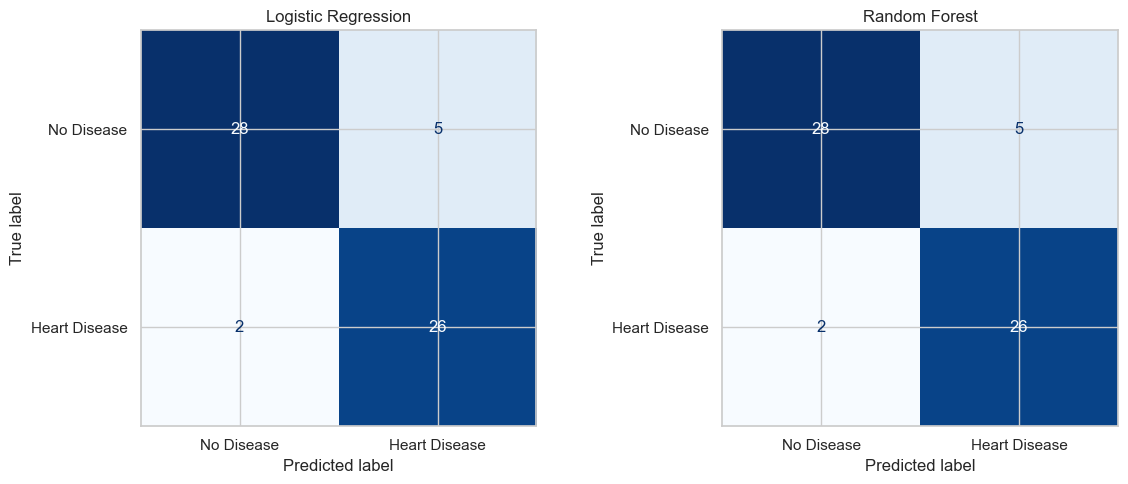

Confusion matrices generated and saved.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures\confusion_matrices.png


In [24]:
# Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, predictions) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_test,
        predictions["y_pred"],
        labels=[0, 1]
    )

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease", "Heart Disease"]
    )

    display_plot.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrices generated and saved.")
print("Location:", (FIGURES_DIR / "confusion_matrices.png").resolve())

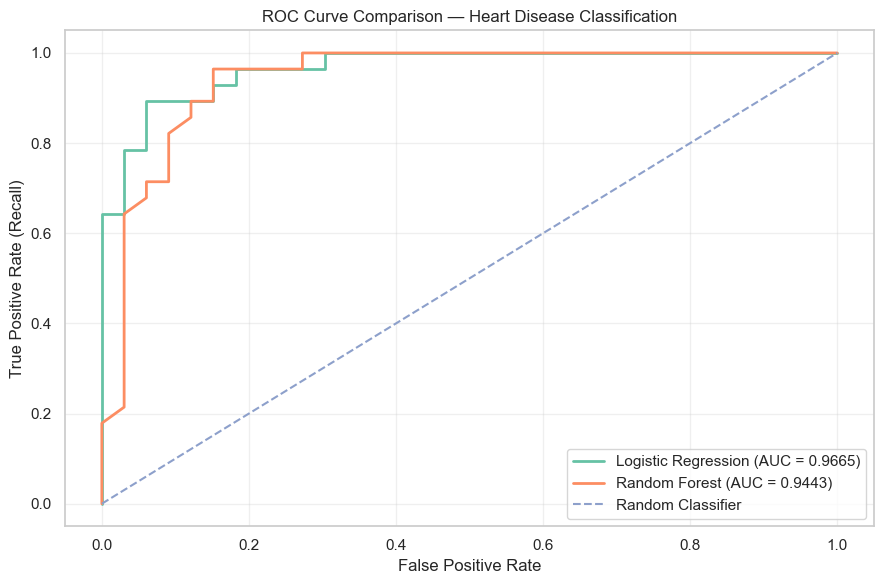

ROC curve comparison generated and saved.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\reports\figures\roc_curve_comparison.png


In [25]:
# ROC Curve Comparison

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for model_name, predictions in test_predictions.items():
    y_prob = predictions["y_prob"]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison — Heart Disease Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve comparison generated and saved.")
print("Location:", (FIGURES_DIR / "roc_curve_comparison.png").resolve())

### Test Set Evaluation and Model Comparison

Both classification models were evaluated on the held-out test set containing 61 patient records.

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 88.52% | 88.52% |
| Precision | 83.87% | 83.87% |
| Recall | 92.86% | 92.86% |
| F1-score | 88.14% | 88.14% |
| ROC-AUC | 0.9665 | 0.9443 |

Both models produced identical class predictions at the default classification threshold. Logistic Regression achieved a higher ROC-AUC, indicating better ranking of positive and negative cases based on predicted probabilities on this test set.

### Initial Model Selection

Logistic Regression is the leading candidate because it achieved the higher cross-validation mean metrics and higher test-set ROC-AUC. The final selection will also consider reproducibility, model tracking, and deployment requirements.

The confusion matrices and ROC curves have been saved in the project's `reports/figures` directory for documentation.

**Limitation:** This evaluation uses a small, historical dataset and is intended for academic experimentation. The results do not establish clinical suitability or real-world diagnostic performance.

## MLflow Experiment Tracking

### Objective

MLflow will be used to track machine learning experiments, record model configurations, log evaluation metrics, and maintain trained model artifacts.

Experiment tracking improves reproducibility and makes it easier to compare model performance across different algorithms and configurations.

### Tracking Plan

For each classification model, we will record:

- **Parameters:** Model type and relevant hyperparameters.
- **Metrics:** Accuracy, precision, recall, F1-score, and ROC-AUC.
- **Artifacts:** Classification reports, confusion matrices, ROC curves, and trained model files where appropriate.
- **Experiment metadata:** Run names and model-selection information.

The experiment results will be stored locally within the project so that runs can be reviewed and compared later.

### Reproducibility

The experiments will use the existing training-test split, fixed random seed, and Scikit-learn pipelines. The test set will remain reserved for evaluation rather than model fitting.

In [26]:
# Check MLflow Installation

try:
    import mlflow

    print("MLflow is installed successfully.")
    print("MLflow version:", mlflow.__version__)

except ImportError:
    print("MLflow is not installed in the current environment.")
    print("Install it using the command below in a separate notebook cell:")
    print("%pip install mlflow")

MLflow is installed successfully.
MLflow version: 3.17.0


In [27]:
%pip install mlflow

In [28]:
# Verify MLflow Installation

import mlflow

print("MLflow imported successfully.")
print("MLflow version:", mlflow.__version__)
print("Experiment tracking is ready to configure.")

MLflow imported successfully.
MLflow version: 3.17.0
Experiment tracking is ready to configure.


In [29]:
# Configure MLflow Using SQLite

# Store experiment metadata in a local SQLite database
MLFLOW_DB_PATH = PROJECT_ROOT / "mlflow.db"
MLFLOW_DB_URI = f"sqlite:///{MLFLOW_DB_PATH.as_posix()}"

mlflow.set_tracking_uri(MLFLOW_DB_URI)

# Create or select the experiment
EXPERIMENT_NAME = "Heart Disease Classification"
mlflow.set_experiment(EXPERIMENT_NAME)

# Retrieve experiment details
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

print("MLflow experiment configured successfully.")
print("MLflow version:", mlflow.__version__)
print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Database location:", MLFLOW_DB_PATH.resolve())

MLflow experiment configured successfully.
MLflow version: 3.17.0
Experiment name: Heart Disease Classification
Experiment ID: 1
Tracking URI: sqlite:///D:/MTECH AI & ML/Semester 3/MLops/Assignment/heart_disease_mlops/mlflow.db
Database location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\mlflow.db


In [30]:
# Log Model Experiments to MLflow

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri(MLFLOW_DB_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

artifact_files = [
    FIGURES_DIR / "confusion_matrices.png",
    FIGURES_DIR / "roc_curve_comparison.png",
]

for model_name, model_pipeline in models.items():

    cv_row = cv_results_df.loc[
        cv_results_df["Model"] == model_name
    ].iloc[0]

    test_row = test_results_df.loc[
        test_results_df["Model"] == model_name
    ].iloc[0]

    with mlflow.start_run(run_name=model_name):

        # Log model configuration
        mlflow.log_params({
            "model_type": model_name,
            "random_state": RANDOM_STATE,
            "test_size": TEST_SIZE,
            "cv_folds": CV_FOLDS,
        })

        # Log cross-validation metrics
        mlflow.log_metrics({
            "cv_accuracy_mean": float(cv_row["Accuracy (Mean)"]),
            "cv_accuracy_std": float(cv_row["Accuracy (Std)"]),
            "cv_precision_mean": float(cv_row["Precision (Mean)"]),
            "cv_recall_mean": float(cv_row["Recall (Mean)"]),
            "cv_f1_mean": float(cv_row["F1-Score (Mean)"]),
            "cv_roc_auc_mean": float(cv_row["ROC-AUC (Mean)"]),
        })

        # Log test-set metrics
        mlflow.log_metrics({
            "test_accuracy": float(test_row["Accuracy"]),
            "test_precision": float(test_row["Precision"]),
            "test_recall": float(test_row["Recall"]),
            "test_f1": float(test_row["F1-Score"]),
            "test_roc_auc": float(test_row["ROC-AUC"]),
        })

        # Log evaluation plots
        for artifact_file in artifact_files:
            if artifact_file.exists():
                mlflow.log_artifact(str(artifact_file))

        # Log the fitted model using Pickle serialization
        mlflow.sklearn.log_model(
            sk_model=model_pipeline,
            name="model",
            serialization_format="pickle"
        )

        print(f"Logged experiment successfully: {model_name}")
        print("Run ID:", mlflow.active_run().info.run_id)

print("\nBoth model experiments have been logged to MLflow.")

2026/10/11 18:02:25 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/11 18:02:25 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

Logged experiment successfully: Logistic Regression
Run ID: e0d88856b327476c89470bf5d71d0d31


2026/10/11 18:02:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged experiment successfully: Random Forest
Run ID: 3fa74d259c924b89bc15fdbe0b886d53

Both model experiments have been logged to MLflow.


In [31]:
# Verify MLflow Experiment Runs

mlflow.set_tracking_uri(MLFLOW_DB_URI)

experiment_runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME]
)

display_columns = [
    "tags.mlflow.runName",
    "status",
    "metrics.test_accuracy",
    "metrics.test_precision",
    "metrics.test_recall",
    "metrics.test_f1",
    "metrics.test_roc_auc",
]

available_columns = [
    column for column in display_columns
    if column in experiment_runs.columns
]

print("Total MLflow runs:", len(experiment_runs))

display(
    experiment_runs[available_columns].sort_values(
        by="tags.mlflow.runName",
        na_position="last"
    ).reset_index(drop=True)
)

Total MLflow runs: 5


,tags.mlflow.runName,status,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc
0,Logistic Regression,FINISHED,0.8852,0.8387,0.9286,0.8814,0.9665
1,Logistic Regression,FINISHED,0.8852,0.8387,0.9286,0.8814,0.9665
2,Logistic Regression,FAILED,0.8852,0.8387,0.9286,0.8814,0.9665
3,Random Forest,FINISHED,0.8852,0.8387,0.9286,0.8814,0.9443
4,Random Forest,FINISHED,0.8852,0.8387,0.9286,0.8814,0.9443



### MLflow Experiment Tracking Dashboard

MLflow is used to track model configurations, cross-validation metrics, test-set performance, evaluation plots, and trained model artifacts.

The experiment results are stored in a local SQLite database (`mlflow.db`) within the project directory.

To launch the MLflow tracking dashboard, open a terminal or Anaconda Prompt, navigate to the project root, activate the same Python environment used by Jupyter, and run:

```bash
mlflow ui --backend-store-uri "sqlite:///mlflow.db" --host 127.0.0.1 --port 5000
```

Then open http://127.0.0.1:5000 in a browser and select the **Heart Disease Classification** experiment.

The dashboard can be used to compare model runs, inspect logged metrics, and review stored artifacts.


In [32]:
# Save the Best-Performing Model

import joblib

BEST_MODEL_NAME = "Logistic Regression"
BEST_MODEL_PATH = MODEL_DIR / "best_heart_disease_model.joblib"

best_model = models[BEST_MODEL_NAME]

joblib.dump(best_model, BEST_MODEL_PATH)

print("Best model saved successfully.")
print("Model:", BEST_MODEL_NAME)
print("Model path:", BEST_MODEL_PATH.resolve())
print("File size (KB):", round(BEST_MODEL_PATH.stat().st_size / 1024, 2))

Best model saved successfully.
Model: Logistic Regression
Model path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\models\best_heart_disease_model.joblib
File size (KB): 5.07


In [33]:
# Verify the Saved Model

import joblib
from sklearn.metrics import accuracy_score

loaded_model = joblib.load(BEST_MODEL_PATH)

sample_predictions = loaded_model.predict(X_test)
loaded_model_accuracy = accuracy_score(y_test, sample_predictions)

print("Saved model loaded successfully.")
print("Test samples:", len(X_test))
print("Predictions generated:", len(sample_predictions))
print(f"Accuracy after reloading: {loaded_model_accuracy:.4f}")
print(
    "Predictions match original model:",
    np.array_equal(sample_predictions, models[BEST_MODEL_NAME].predict(X_test))
)

Saved model loaded successfully.
Test samples: 61
Predictions generated: 61
Accuracy after reloading: 0.8852
Predictions match original model: True


In [34]:
# Generate Prediction Probabilities

test_probabilities = loaded_model.predict_proba(X_test)[:, 1]

prediction_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": sample_predictions,
    "Disease_Probability": test_probabilities
}, index=X_test.index)

print("Prediction results for the first 10 test samples:")
display(prediction_results.head(10).round(4))

print("\nProbability summary:")
display(prediction_results["Disease_Probability"].describe().round(4))

Prediction results for the first 10 test samples:


,Actual,Predicted,Disease_Probability
219,0,0,0.2093
271,0,1,0.6015
89,0,0,0.0215
101,0,0,0.0333
67,0,0,0.3118
244,0,0,0.0156
185,0,0,0.1168
233,0,0,0.3486
168,1,1,0.7221
197,0,0,0.3474



Probability summary:


count    61.0000
mean      0.5045
std       0.3851
min       0.0132
25%       0.0904
50%       0.5079
75%       0.9100
max       0.9898
Name: Disease_Probability, dtype: float64

In [35]:
# Save Prediction Results

PREDICTIONS_FILE = PROCESSED_DATA_DIR / "test_prediction_results.csv"

prediction_results.to_csv(PREDICTIONS_FILE, index=True, index_label="Sample_Index")

print("Prediction results saved successfully.")
print("File path:", PREDICTIONS_FILE.resolve())
print("Number of saved predictions:", len(prediction_results))
print("File exists:", PREDICTIONS_FILE.exists())

Prediction results saved successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\data\processed\test_prediction_results.csv
Number of saved predictions: 61
File exists: True


In [36]:
# Create a Reusable Prediction Function

def predict_heart_disease(input_data, model=loaded_model):
    """
    Predict heart disease presence for one or more samples.

    Parameters
    ----------
    input_data : pandas.DataFrame
        Input data containing the 13 required model features.

    model : fitted sklearn pipeline
        Saved preprocessing and classification pipeline.

    Returns
    -------
    pandas.DataFrame
        Predicted class and estimated disease probability.
    """
    missing_features = set(ALL_FEATURES) - set(input_data.columns)

    if missing_features:
        raise ValueError(
            f"Missing required features: {sorted(missing_features)}"
        )

    input_data = input_data[ALL_FEATURES].copy()

    predictions = model.predict(input_data)
    probabilities = model.predict_proba(input_data)[:, 1]

    return pd.DataFrame({
        "Predicted": predictions,
        "Disease_Probability": probabilities
    }, index=input_data.index)


print("Reusable prediction function created successfully.")

Reusable prediction function created successfully.


In [37]:
# Test the Reusable Prediction Function

sample_input = X_test.iloc[:2].copy()

sample_output = predict_heart_disease(sample_input)

sample_comparison = pd.DataFrame({
    "Actual": y_test.loc[sample_input.index],
    "Predicted": sample_output["Predicted"],
    "Disease_Probability": sample_output["Disease_Probability"]
}, index=sample_input.index)

print("Sample predictions:")
display(sample_comparison.round(4))

print("\nPrediction function validation:")
print("Input samples:", len(sample_input))
print("Output samples:", len(sample_output))
print("All probabilities within [0, 1]:",
      sample_output["Disease_Probability"].between(0, 1).all())
print("Output contains missing values:", sample_output.isna().any().any())

Sample predictions:


,Actual,Predicted,Disease_Probability
219,0,0,0.2093
271,0,1,0.6015



Prediction function validation:
Input samples: 2
Output samples: 2
All probabilities within [0, 1]: True
Output contains missing values: False


In [38]:
# Validate Missing-Feature Handling

incomplete_input = X_test.iloc[:1].drop(columns=["age"])

try:
    predict_heart_disease(incomplete_input)
except ValueError as error:
    print("Invalid input handled correctly.")
    print("Validation message:", error)
else:
    raise AssertionError(
        "Expected ValueError for missing required feature."
    )

print("\nInput validation test passed.")

Invalid input handled correctly.
Validation message: Missing required features: ['age']

Input validation test passed.


In [39]:
# Create the Reusable Prediction Module

PREDICTION_MODULE_PATH = PROJECT_ROOT / "src" / "predict.py"

prediction_module_code = '''
from pathlib import Path

import joblib
import pandas as pd

PROJECT_ROOT = Path(__file__).resolve().parents[1]
MODEL_PATH = PROJECT_ROOT / "models" / "best_heart_disease_model.joblib"

NUMERICAL_FEATURES = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

CATEGORICAL_FEATURES = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

ALL_FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES


def load_model():
    """Load the saved, trusted scikit-learn pipeline."""
    return joblib.load(MODEL_PATH)


def predict_heart_disease(input_data, model=None):
    """Return predicted classes and estimated disease probabilities."""
    if not isinstance(input_data, pd.DataFrame):
        raise TypeError("input_data must be a pandas DataFrame.")

    missing_features = set(ALL_FEATURES) - set(input_data.columns)
    if missing_features:
        raise ValueError(
            f"Missing required features: {sorted(missing_features)}"
        )

    input_data = input_data[ALL_FEATURES].copy()

    if model is None:
        model = load_model()

    predictions = model.predict(input_data)
    probabilities = model.predict_proba(input_data)[:, 1]

    return pd.DataFrame({
        "Predicted": predictions,
        "Disease_Probability": probabilities
    }, index=input_data.index)
'''

PREDICTION_MODULE_PATH.write_text(
    prediction_module_code.strip() + "\n",
    encoding="utf-8"
)

print("Prediction module created successfully.")
print("File path:", PREDICTION_MODULE_PATH.resolve())
print("File exists:", PREDICTION_MODULE_PATH.exists())

Prediction module created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\src\predict.py
File exists: True


In [40]:
# Test the Standalone Prediction Module

import importlib.util

MODULE_SPEC = importlib.util.spec_from_file_location(
    "heart_disease_predict",
    PREDICTION_MODULE_PATH
)

prediction_module = importlib.util.module_from_spec(MODULE_SPEC)
MODULE_SPEC.loader.exec_module(prediction_module)

module_predictions = prediction_module.predict_heart_disease(
    X_test.iloc[:5]
)

notebook_predictions = predict_heart_disease(X_test.iloc[:5])

print("Standalone module imported successfully.")
print("Model loaded from saved artifact.")
print("Number of predictions:", len(module_predictions))
print(
    "Predictions match notebook function:",
    np.array_equal(
        module_predictions["Predicted"].to_numpy(),
        notebook_predictions["Predicted"].to_numpy()
    )
)
print(
    "Probabilities match notebook function:",
    np.allclose(
        module_predictions["Disease_Probability"].to_numpy(),
        notebook_predictions["Disease_Probability"].to_numpy()
    )
)

display(module_predictions.round(4))

Standalone module imported successfully.
Model loaded from saved artifact.
Number of predictions: 5
Predictions match notebook function: True
Probabilities match notebook function: True


,Predicted,Disease_Probability
219,0,0.2093
271,1,0.6015
89,0,0.0215
101,0,0.0333
67,0,0.3118


In [41]:
# Create Automated Unit Tests

TEST_FILE_PATH = PROJECT_ROOT / "tests" / "test_predict.py"

test_code = '''
import sys
from pathlib import Path

import pandas as pd
import pytest

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predict import ALL_FEATURES, predict_heart_disease


@pytest.fixture
def sample_input():
    """Create a valid sample using a row from the UCI test data."""
    return pd.DataFrame([{
        "age": 63,
        "sex": 1,
        "cp": 1,
        "trestbps": 145,
        "chol": 233,
        "fbs": 1,
        "restecg": 2,
        "thalach": 150,
        "exang": 0,
        "oldpeak": 2.3,
        "slope": 3,
        "ca": 0,
        "thal": 6,
    }], columns=ALL_FEATURES)


def test_prediction_output_structure(sample_input):
    result = predict_heart_disease(sample_input)

    assert len(result) == 1
    assert list(result.columns) == [
        "Predicted", "Disease_Probability"
    ]


def test_prediction_values(sample_input):
    result = predict_heart_disease(sample_input)

    assert result["Predicted"].isin([0, 1]).all()
    assert result["Disease_Probability"].between(0, 1).all()


def test_missing_feature_is_rejected(sample_input):
    incomplete_input = sample_input.drop(columns=["age"])

    with pytest.raises(ValueError, match="age"):
        predict_heart_disease(incomplete_input)


def test_non_dataframe_input_is_rejected():
    with pytest.raises(TypeError, match="DataFrame"):
        predict_heart_disease([1, 2, 3])
'''

TEST_FILE_PATH.write_text(
    test_code.strip() + "\n",
    encoding="utf-8"
)

print("Automated test file created successfully.")
print("File path:", TEST_FILE_PATH.resolve())
print("File exists:", TEST_FILE_PATH.exists())

Automated test file created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\tests\test_predict.py
File exists: True


In [42]:
# Run Automated Tests

import subprocess

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        str(TEST_FILE_PATH),
        "-v"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print("Additional output:")
    print(test_result.stderr)

print("Pytest exit code:", test_result.returncode)

if test_result.returncode != 0:
    print("Some tests failed. Review the output above.")
else:
    print("All automated tests passed.")

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- C:\ProgramData\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops
plugins: anyio-4.7.0
collecting ... collected 4 items

tests/test_predict.py::test_prediction_output_structure PASSED           [ 25%]
tests/test_predict.py::test_prediction_values PASSED                     [ 50%]
tests/test_predict.py::test_missing_feature_is_rejected PASSED           [ 75%]
tests/test_predict.py::test_non_dataframe_input_is_rejected PASSED       [100%]

============================== 4 passed in 2.66s ==============================

Pytest exit code: 0
All automated tests passed.


In [43]:
# Create requirements.txt

REQUIREMENTS_FILE = PROJECT_ROOT / "requirements.txt"

requirements_content = """numpy
pandas
matplotlib
seaborn
scikit-learn
mlflow
joblib
pytest
fastapi
uvicorn
pydantic
"""

REQUIREMENTS_FILE.write_text(
    requirements_content,
    encoding="utf-8"
)

print("requirements.txt created successfully.")
print("File path:", REQUIREMENTS_FILE.resolve())
print("\nDeclared dependencies:")
print(REQUIREMENTS_FILE.read_text(encoding="utf-8"))

requirements.txt created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\requirements.txt

Declared dependencies:
numpy
pandas
matplotlib
seaborn
scikit-learn
mlflow
joblib
pytest
fastapi
uvicorn
pydantic



In [44]:
# Record Installed Package Versions

import importlib.metadata as metadata

PACKAGE_NAMES = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "mlflow",
    "joblib",
    "pytest",
    "fastapi",
    "uvicorn",
    "pydantic",
]

installed_versions = {}

for package in PACKAGE_NAMES:
    try:
        installed_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed_versions[package] = "Not installed"

versions_df = pd.DataFrame(
    list(installed_versions.items()),
    columns=["Package", "Installed Version"]
)

display(versions_df)

print("Python version:", sys.version.split()[0])


,Package,Installed Version
0,numpy,2.1.3
1,pandas,2.2.3
2,matplotlib,3.10.0
3,seaborn,0.13.2
4,scikit-learn,1.6.1
5,mlflow,3.17.0
6,joblib,1.4.2
7,pytest,8.3.4
8,fastapi,0.143.0
9,uvicorn,0.54.0


Python version: 3.13.5


In [45]:
# Create a Version-Pinned Dependency File

LOCK_FILE = PROJECT_ROOT / "requirements-lock.txt"

locked_requirements = "\n".join(
    f"{package}=={version}"
    for package, version in installed_versions.items()
    if version != "Not installed"
) + "\n"

LOCK_FILE.write_text(
    locked_requirements,
    encoding="utf-8"
)

print("Version-pinned dependency file created.")
print("File path:", LOCK_FILE.resolve())
print("\nPinned direct dependencies:")
print(LOCK_FILE.read_text(encoding="utf-8"))


Version-pinned dependency file created.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\requirements-lock.txt

Pinned direct dependencies:
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
mlflow==3.17.0
joblib==1.4.2
pytest==8.3.4
fastapi==0.143.0
uvicorn==0.54.0
pydantic==2.10.3



In [46]:
# Create the FastAPI Application

API_FILE_PATH = PROJECT_ROOT / "api" / "main.py"

api_code = '''
import sys
from pathlib import Path

import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

PROJECT_ROOT = Path(__file__).resolve().parents[1]
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from predict import ALL_FEATURES, load_model, predict_heart_disease

app = FastAPI(
    title="Heart Disease Prediction API",
    description=(
        "Academic ML demonstration using the UCI Cleveland "
        "Heart Disease dataset. Not intended for clinical use."
    ),
    version="1.0.0",
)


class PatientFeatures(BaseModel):
    age: float = Field(ge=0, le=120)
    sex: int = Field(ge=0, le=1)
    cp: int = Field(ge=1, le=4)
    trestbps: float = Field(gt=0)
    chol: float = Field(gt=0)
    fbs: int = Field(ge=0, le=1)
    restecg: int = Field(ge=0, le=2)
    thalach: float = Field(gt=0)
    exang: int = Field(ge=0, le=1)
    oldpeak: float
    slope: int = Field(ge=1, le=3)
    ca: float = Field(ge=0, le=3)
    thal: int = Field(ge=3, le=7)


@app.get("/")
def root():
    return {
        "service": "Heart Disease Prediction API",
        "status": "running",
        "docs": "/docs",
    }


@app.get("/health")
def health():
    try:
        load_model()
        return {"status": "healthy", "model_loaded": True}
    except Exception:
        raise HTTPException(
            status_code=503,
            detail="Model could not be loaded."
        )


@app.post("/predict")
def predict(patient: PatientFeatures):
    try:
        patient_data = pd.DataFrame(
            [patient.model_dump()],
            columns=ALL_FEATURES
        )
        result = predict_heart_disease(patient_data)

        predicted_class = int(result["Predicted"].iloc[0])
        probability = float(
            result["Disease_Probability"].iloc[0]
        )

        return {
            "predicted_class": predicted_class,
            "prediction_label": (
                "heart_disease" if predicted_class == 1
                else "no_heart_disease"
            ),
            "estimated_probability": round(probability, 4),
            "disclaimer": (
                "For educational demonstration only; "
                "not a medical diagnosis."
            ),
        }
    except Exception:
        raise HTTPException(
            status_code=500,
            detail="Prediction failed."
        )
'''

API_FILE_PATH.write_text(
    api_code.strip() + "\n",
    encoding="utf-8"
)

print("FastAPI application created successfully.")
print("File path:", API_FILE_PATH.resolve())
print("File exists:", API_FILE_PATH.exists())


FastAPI application created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\api\main.py
File exists: True


In [47]:
# Test the FastAPI Endpoints

from fastapi.testclient import TestClient
import importlib.util

API_SPEC = importlib.util.spec_from_file_location(
    "heart_disease_api",
    API_FILE_PATH
)
api_module = importlib.util.module_from_spec(API_SPEC)
API_SPEC.loader.exec_module(api_module)

client = TestClient(api_module.app)

# Test the root endpoint
root_response = client.get("/")
print("Root endpoint:", root_response.status_code, root_response.json())

# Test the health endpoint
health_response = client.get("/health")
print("Health endpoint:", health_response.status_code, health_response.json())

# Test a valid prediction request
sample_patient = X_test.iloc[0].to_dict()
sample_patient = {
    key: value.item() if isinstance(value, np.generic) else value
    for key, value in sample_patient.items()
}

prediction_response = client.post("/predict", json=sample_patient)
print("Prediction endpoint status:", prediction_response.status_code)
print("Prediction response:", prediction_response.json())

# Test invalid input: omit a required feature
invalid_patient = sample_patient.copy()
invalid_patient.pop("age")

invalid_response = client.post("/predict", json=invalid_patient)
print("Invalid-input status:", invalid_response.status_code)

assert root_response.status_code == 200
assert health_response.status_code == 200
assert prediction_response.status_code == 200
assert invalid_response.status_code == 422

print("\nAll API endpoint checks passed.")

Root endpoint: 200 {'service': 'Heart Disease Prediction API', 'status': 'running', 'docs': '/docs'}
Health endpoint: 200 {'status': 'healthy', 'model_loaded': True}
Prediction endpoint status: 200
Prediction response: {'predicted_class': 0, 'prediction_label': 'no_heart_disease', 'estimated_probability': 0.2093, 'disclaimer': 'For educational demonstration only; not a medical diagnosis.'}
Invalid-input status: 422

All API endpoint checks passed.


In [48]:
# Create API Tests

API_TEST_FILE = PROJECT_ROOT / "tests" / "test_api.py"

api_test_code = '''
import sys
from pathlib import Path

from fastapi.testclient import TestClient

PROJECT_ROOT = Path(__file__).resolve().parents[1]
API_DIR = PROJECT_ROOT / "api"

sys.path.insert(0, str(API_DIR))

from main import app

client = TestClient(app)


def test_root_endpoint():
    response = client.get("/")
    assert response.status_code == 200
    assert response.json()["status"] == "running"


def test_health_endpoint():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["model_loaded"] is True


def test_prediction_endpoint():
    patient = {
        "age": 63,
        "sex": 1,
        "cp": 1,
        "trestbps": 145,
        "chol": 233,
        "fbs": 1,
        "restecg": 2,
        "thalach": 150,
        "exang": 0,
        "oldpeak": 2.3,
        "slope": 3,
        "ca": 0,
        "thal": 6
    }

    response = client.post("/predict", json=patient)

    assert response.status_code == 200
    result = response.json()
    assert result["predicted_class"] in [0, 1]
    assert 0 <= result["estimated_probability"] <= 1
    assert "disclaimer" in result


def test_prediction_rejects_missing_feature():
    patient = {
        "sex": 1,
        "cp": 1,
        "trestbps": 145,
        "chol": 233,
        "fbs": 1,
        "restecg": 2,
        "thalach": 150,
        "exang": 0,
        "oldpeak": 2.3,
        "slope": 3,
        "ca": 0,
        "thal": 6
    }

    response = client.post("/predict", json=patient)
    assert response.status_code == 422
'''

API_TEST_FILE.write_text(
    api_test_code.strip() + "\n",
    encoding="utf-8"
)

print("API test file created successfully.")
print("File path:", API_TEST_FILE.resolve())
print("File exists:", API_TEST_FILE.exists())

API test file created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\tests\test_api.py
File exists: True


In [49]:
# Run All Project Tests

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        str(PROJECT_ROOT / "tests"),
        "-v"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print("Additional output:")
    print(test_result.stderr)

print("Pytest exit code:", test_result.returncode)

if test_result.returncode == 0:
    print("All project tests passed.")
else:
    print("Some tests failed. Review the output above.")

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- C:\ProgramData\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops
plugins: anyio-4.7.0
collecting ... collected 8 items

tests/test_api.py::test_root_endpoint PASSED                             [ 12%]
tests/test_api.py::test_health_endpoint PASSED                           [ 25%]
tests/test_api.py::test_prediction_endpoint PASSED                       [ 37%]
tests/test_api.py::test_prediction_rejects_missing_feature PASSED        [ 50%]
tests/test_predict.py::test_prediction_output_structure PASSED           [ 62%]
tests/test_predict.py::test_prediction_values PASSED                     [ 75%]
tests/test_predict.py::test_missing_feature_is_rejected PASSED           [ 87%]
tests/test_predict.py::test_non_dataframe_input_is_rejected PASSED       [100%]

===========================

In [50]:
# Create Dockerfile

DOCKERFILE_PATH = PROJECT_ROOT / "Dockerfile"

dockerfile_content = """
FROM python:3.13-slim

WORKDIR /app

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

COPY requirements-lock.txt ./requirements-lock.txt

RUN pip install --no-cache-dir --upgrade pip \\
    && pip install --no-cache-dir -r requirements-lock.txt

COPY src/ ./src/
COPY api/ ./api/
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "main:app", "--app-dir", "api", "--host", "0.0.0.0", "--port", "8000"]
"""

DOCKERFILE_PATH.write_text(
    dockerfile_content.strip() + "\n",
    encoding="utf-8"
)

print("Dockerfile created successfully.")
print("File path:", DOCKERFILE_PATH.resolve())
print("\nDockerfile contents:")
print(DOCKERFILE_PATH.read_text(encoding="utf-8"))

Dockerfile created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\Dockerfile

Dockerfile contents:
FROM python:3.13-slim

WORKDIR /app

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

COPY requirements-lock.txt ./requirements-lock.txt

RUN pip install --no-cache-dir --upgrade pip \
    && pip install --no-cache-dir -r requirements-lock.txt

COPY src/ ./src/
COPY api/ ./api/
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "main:app", "--app-dir", "api", "--host", "0.0.0.0", "--port", "8000"]



In [51]:
# Create API-Specific Requirements

API_REQUIREMENTS_FILE = PROJECT_ROOT / "requirements-api.txt"

api_requirements = """numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.4.2
fastapi==0.143.0
uvicorn==0.54.0
pydantic==2.10.3
"""

API_REQUIREMENTS_FILE.write_text(
    api_requirements,
    encoding="utf-8"
)

print("API requirements file created successfully.")
print("File path:", API_REQUIREMENTS_FILE.resolve())
print("\nContents:")
print(API_REQUIREMENTS_FILE.read_text(encoding="utf-8"))

API requirements file created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\requirements-api.txt

Contents:
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.4.2
fastapi==0.143.0
uvicorn==0.54.0
pydantic==2.10.3



In [52]:
# Update Dockerfile for API Deployment

dockerfile_content = """
FROM python:3.13-slim

WORKDIR /app

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

COPY requirements-api.txt ./requirements-api.txt

RUN pip install --no-cache-dir --upgrade pip \\
    && pip install --no-cache-dir -r requirements-api.txt

COPY src/ ./src/
COPY api/ ./api/
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "main:app", "--app-dir", "api", "--host", "0.0.0.0", "--port", "8000"]
"""

DOCKERFILE_PATH.write_text(
    dockerfile_content.strip() + "\n",
    encoding="utf-8"
)

print("Dockerfile updated successfully.")
print("\nUpdated Dockerfile:")
print(DOCKERFILE_PATH.read_text(encoding="utf-8"))

Dockerfile updated successfully.

Updated Dockerfile:
FROM python:3.13-slim

WORKDIR /app

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

COPY requirements-api.txt ./requirements-api.txt

RUN pip install --no-cache-dir --upgrade pip \
    && pip install --no-cache-dir -r requirements-api.txt

COPY src/ ./src/
COPY api/ ./api/
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "main:app", "--app-dir", "api", "--host", "0.0.0.0", "--port", "8000"]



In [53]:
# Create .dockerignore

DOCKERIGNORE_PATH = PROJECT_ROOT / ".dockerignore"

dockerignore_content = """
.git/
.gitignore
.ipynb_checkpoints/
__pycache__/
*.py[cod]
.pytest_cache/
.venv/
venv/
.env
.env.*
data/
notebooks/
mlruns/
mlflow.db
logs/
reports/
tests/
deployment/
"""

DOCKERIGNORE_PATH.write_text(
    dockerignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".dockerignore created successfully.")
print("File path:", DOCKERIGNORE_PATH.resolve())
print("\nContents:")
print(DOCKERIGNORE_PATH.read_text(encoding="utf-8"))


.dockerignore created successfully.
File path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\.dockerignore

Contents:
.git/
.gitignore
.ipynb_checkpoints/
__pycache__/
*.py[cod]
.pytest_cache/
.venv/
venv/
.env
.env.*
data/
notebooks/
mlruns/
mlflow.db
logs/
reports/
tests/
deployment/



In [56]:
# Verify Docker Engine from Jupyter

import shutil
import subprocess

docker_path = shutil.which("docker")
print("Docker executable:", docker_path)

if docker_path is None:
    print("Docker CLI is not on Jupyter's PATH.")
    print("Restart Jupyter Notebook and run this cell again.")
else:
    result = subprocess.run(
        ["docker", "info"],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        print("Docker engine is running successfully.")
        print("\nDocker version information:")
        version_result = subprocess.run(
            ["docker", "--version"],
            capture_output=True,
            text=True
        )
        print(version_result.stdout.strip())
    else:
        print("Docker engine check failed:")
        print(result.stderr.strip())


Docker executable: C:\Users\Harsh Shah\AppData\Local\Programs\DockerDesktop\resources\bin\docker.EXE
Docker engine is running successfully.

Docker version information:
Docker version 29.8.2, build 7fc2dff


In [57]:
# Build the Heart Disease Prediction Docker Image

import subprocess

IMAGE_NAME = "heart-disease-api"
IMAGE_TAG = "1.0"

build_command = [
    "docker", "build",
    "-t", f"{IMAGE_NAME}:{IMAGE_TAG}",
    "-f", str(PROJECT_ROOT / "Dockerfile"),
    str(PROJECT_ROOT)
]

print("Building Docker image...")
print("Image:", f"{IMAGE_NAME}:{IMAGE_TAG}")
print("Build context:", PROJECT_ROOT)

build_result = subprocess.run(
    build_command,
    capture_output=True,
    text=True
)

print("\n--- Docker Build Output ---")
print(build_result.stdout)

if build_result.stderr:
    print("\n--- Docker Build Messages / Errors ---")
    print(build_result.stderr)

if build_result.returncode == 0:
    print("\nDocker image built successfully.")
else:
    print("\nDocker image build failed. Share the complete output.")


Building Docker image...
Image: heart-disease-api:1.0
Build context: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops

--- Docker Build Output ---


--- Docker Build Messages / Errors ---
Failed to initialize: unable to resolve docker endpoint: context "desktop-linux": open C:\Users\Harsh Shah\.docker\contexts\meta\fe9c6bd7a66301f49ca9b6a70b217107cd1284598bfc254700c989b916da791e\meta.json: The process cannot access the file because it is being used by another process.


Docker image build failed. Share the complete output.


In [58]:
# Inspect Docker Contexts

import subprocess

for command in [
    ["docker", "context", "show"],
    ["docker", "context", "ls"],
    ["docker", "info"],
]:
    print("\n$", " ".join(command))
    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )
    print(result.stdout.strip())
    if result.stderr.strip():
        print("Error:", result.stderr.strip())
    print("Exit code:", result.returncode)



$ docker context show
desktop-linux
Exit code: 0

$ docker context ls
NAME              DESCRIPTION                               DOCKER ENDPOINT                             ERROR
default           Current DOCKER_HOST based configuration   npipe:////./pipe/docker_engine              
desktop-linux *   Docker Desktop                            npipe:////./pipe/dockerDesktopLinuxEngine
Exit code: 0

$ docker info
Client:
 Version:    29.8.2
 Context:    desktop-linux
 Debug Mode: false
 Plugins:
  agent: Docker AI Agent Runner (Docker Inc.)
    Version:  v1.144.0
    Path:     C:\Users\Harsh Shah\.docker\cli-plugins\docker-agent.exe
  ai: Docker AI Agent - Ask Gordon (Docker Inc.)
    Version:  v1.31.0
    Path:     C:\Users\Harsh Shah\.docker\cli-plugins\docker-ai.exe
  buildx: Docker Buildx (Docker Inc.)
    Version:  v0.37.2
    Path:     C:\Users\Harsh Shah\.docker\cli-plugins\docker-buildx.exe
  compose: Docker Compose (Docker Inc.)
    Version:  v5.5.1
    Path:     C:\Users\Harsh

In [61]:
# Build the Heart Disease Prediction API Image

import subprocess

IMAGE_NAME = "heart-disease-api"
IMAGE_TAG = "1.0"

build_command = [
    "docker", "build",
    "--progress=plain",
    "-t", f"{IMAGE_NAME}:{IMAGE_TAG}",
    "-f", str(PROJECT_ROOT / "Dockerfile"),
    str(PROJECT_ROOT)
]

print("Building:", f"{IMAGE_NAME}:{IMAGE_TAG}")
print("Project root:", PROJECT_ROOT)

build_result = subprocess.run(
    build_command,
    capture_output=True,
    text=True
)

print("\n--- Build Output ---")
print(build_result.stdout)

if build_result.stderr:
    print("\n--- Build Messages ---")
    print(build_result.stderr)

if build_result.returncode == 0:
    print("\nSUCCESS: Docker image built successfully.")
else:
    print("\nFAILED: Docker image build did not complete.")
    print("Share the output above so we can identify the cause.")

Building: heart-disease-api:1.0
Project root: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops

--- Build Output ---


--- Build Messages ---
#0 building with "desktop-linux" instance using docker driver

#1 [internal] load build definition from Dockerfile
#1 DONE 0.0s

#1 [internal] load build definition from Dockerfile
#1 transferring dockerfile: 463B 0.0s done
#1 DONE 0.0s

#2 [internal] load metadata for docker.io/library/python:3.13-slim
#2 DONE 0.4s

#3 [internal] load .dockerignore
#3 transferring context: 229B done
#3 DONE 0.0s

#4 [internal] load build context
#4 transferring context: 421B done
#4 DONE 0.0s

#5 [1/7] FROM docker.io/library/python:3.13-slim@sha256:70729b46c69b4f1e97c4822c1af3df53a1476cf5ddc6c087c0c10bc3a5678c2f
#5 resolve docker.io/library/python:3.13-slim@sha256:70729b46c69b4f1e97c4822c1af3df53a1476cf5ddc6c087c0c10bc3a5678c2f 0.0s done
#5 DONE 0.0s

#6 [6/7] COPY api/ ./api/
#6 CACHED

#7 [2/7] WORKDIR /app
#7 CACHED

#8 [4/7] RUN pip install -

In [62]:
# Verify the Docker Image

import subprocess

verify_result = subprocess.run(
    [
        "docker", "image", "ls",
        "--filter", "reference=heart-disease-api:1.0"
    ],
    capture_output=True,
    text=True
)

print(verify_result.stdout)

if verify_result.returncode == 0 and "heart-disease-api" in verify_result.stdout:
    print("SUCCESS: Heart Disease API image is available locally.")
else:
    print("Image verification failed.")
    print(verify_result.stderr)


IMAGE                   ID             DISK USAGE   CONTENT SIZE   EXTRA
heart-disease-api:1.0   32515dd3f7e4        667MB          154MB        

SUCCESS: Heart Disease API image is available locally.


In [63]:
# Run the Heart Disease API Container

import subprocess

CONTAINER_NAME = "heart-disease-api-container"
API_PORT = 8000

# Remove an earlier container with the same name, if one exists.
existing = subprocess.run(
    ["docker", "container", "inspect", CONTAINER_NAME],
    capture_output=True,
    text=True
)

if existing.returncode == 0:
    subprocess.run(
        ["docker", "rm", "-f", CONTAINER_NAME],
        capture_output=True,
        text=True,
        check=True
    )
    print("Removed the previous container.")

run_command = [
    "docker", "run",
    "-d",
    "--name", CONTAINER_NAME,
    "-p", f"{API_PORT}:8000",
    "--restart", "unless-stopped",
    f"{IMAGE_NAME}:{IMAGE_TAG}"
]

run_result = subprocess.run(
    run_command,
    capture_output=True,
    text=True
)

if run_result.returncode == 0:
    print("Container started successfully.")
    print("Container ID:", run_result.stdout.strip())
    print("API URL: http://127.0.0.1:8000")
    print("Swagger documentation: http://127.0.0.1:8000/docs")
else:
    print("Container startup failed:")
    print(run_result.stderr.strip())

Container started successfully.
Container ID: 93a42f1b5d4b46f4f6760fc5afd6152b8be5d1ce44562a61f4cdef2fcbe3660f
API URL: http://127.0.0.1:8000
Swagger documentation: http://127.0.0.1:8000/docs


In [64]:
# Verify Container Status and API Health

import subprocess
import json
import urllib.request
import urllib.error

# Check Docker container status
status_result = subprocess.run(
    [
        "docker", "container", "inspect",
        "--format", "{{.State.Status}}",
        CONTAINER_NAME
    ],
    capture_output=True,
    text=True
)

container_status = status_result.stdout.strip()
print("Container status:", container_status)

# Check API health endpoint
health_url = "http://127.0.0.1:8000/health"

try:
    with urllib.request.urlopen(health_url, timeout=10) as response:
        health_data = json.loads(response.read().decode("utf-8"))
        print("Health endpoint status:", response.status)
        print("Health response:", health_data)

    if container_status == "running" and health_data.get("status") == "healthy":
        print("\nSUCCESS: Container and API are healthy.")
    else:
        print("\nCheck the container logs for details.")

except Exception as exc:
    print("Health check failed:", str(exc))
    logs_result = subprocess.run(
        ["docker", "logs", "--tail", "100", CONTAINER_NAME],
        capture_output=True,
        text=True
    )
    print("\nContainer logs:")
    print(logs_result.stdout)
    if logs_result.stderr:
        print(logs_result.stderr)


Container status: running
Health endpoint status: 200
Health response: {'status': 'healthy', 'model_loaded': True}

SUCCESS: Container and API are healthy.


In [65]:
# Test Prediction Through the Dockerized API

import json
import urllib.request
import urllib.error

API_PREDICT_URL = "http://127.0.0.1:8000/predict"

# Example patient record using valid UCI Cleveland dataset feature values
sample_patient = {
    "age": 63,
    "sex": 1,
    "cp": 1,
    "trestbps": 145,
    "chol": 233,
    "fbs": 1,
    "restecg": 0,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 2.3,
    "slope": 3,
    "ca": 0,
    "thal": 6
}

request_data = json.dumps(sample_patient).encode("utf-8")

request = urllib.request.Request(
    API_PREDICT_URL,
    data=request_data,
    headers={"Content-Type": "application/json"},
    method="POST"
)

try:
    with urllib.request.urlopen(request, timeout=15) as response:
        prediction_result = json.loads(response.read().decode("utf-8"))

        print("HTTP status:", response.status)
        print("\nInput patient features:")
        print(json.dumps(sample_patient, indent=2))

        print("\nAPI prediction response:")
        print(json.dumps(prediction_result, indent=2))

        assert response.status == 200
        assert prediction_result["predicted_class"] in [0, 1]
        assert 0.0 <= prediction_result["estimated_probability"] <= 1.0

        print("\nSUCCESS: Dockerized prediction API returned a valid prediction.")

except urllib.error.HTTPError as exc:
    print("API returned HTTP error:", exc.code)
    print(exc.read().decode("utf-8"))
except Exception as exc:
    print("Prediction test failed:", str(exc))


HTTP status: 200

Input patient features:
{
  "age": 63,
  "sex": 1,
  "cp": 1,
  "trestbps": 145,
  "chol": 233,
  "fbs": 1,
  "restecg": 0,
  "thalach": 150,
  "exang": 0,
  "oldpeak": 2.3,
  "slope": 3,
  "ca": 0,
  "thal": 6
}

API prediction response:
{
  "predicted_class": 0,
  "prediction_label": "no_heart_disease",
  "estimated_probability": 0.1206,
  "disclaimer": "For educational demonstration only; not a medical diagnosis."
}

SUCCESS: Dockerized prediction API returned a valid prediction.


In [66]:
# Verify API Root Endpoint

import json
import urllib.request

API_ROOT_URL = "http://127.0.0.1:8000/"

with urllib.request.urlopen(API_ROOT_URL, timeout=10) as response:
    root_data = json.loads(response.read().decode("utf-8"))

    print("HTTP status:", response.status)
    print("Root endpoint response:")
    print(json.dumps(root_data, indent=2))

    assert response.status == 200
    assert root_data.get("status") == "running"
    assert root_data.get("docs") == "/docs"

    print("\nSUCCESS: API root endpoint is working.")


HTTP status: 200
Root endpoint response:
{
  "service": "Heart Disease Prediction API",
  "status": "running",
  "docs": "/docs"
}

SUCCESS: API root endpoint is working.


In [67]:
# Inspect Docker Container Logs

import subprocess

logs_result = subprocess.run(
    [
        "docker",
        "logs",
        "--tail",
        "100",
        CONTAINER_NAME
    ],
    capture_output=True,
    text=True
)

print("Container logs:\n")

if logs_result.stdout.strip():
    print(logs_result.stdout)

if logs_result.stderr.strip():
    print("\nAdditional logs:")
    print(logs_result.stderr)

if logs_result.returncode == 0:
    print("\nSUCCESS: Container logs retrieved.")
else:
    print("\nERROR: Could not retrieve container logs.")
    print(logs_result.returncode)

Container logs:

INFO:     172.17.0.1:37272 - "GET /health HTTP/1.1" 200 OK
INFO:     172.17.0.1:45404 - "POST /predict HTTP/1.1" 200 OK
INFO:     172.17.0.1:48496 - "GET / HTTP/1.1" 200 OK


Additional logs:
INFO:     Started server process [1]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


SUCCESS: Container logs retrieved.


In [68]:
# Verify Docker Image Details

import subprocess

IMAGE_NAME = "heart-disease-api:1.0"

image_result = subprocess.run(
    [
        "docker", "image", "inspect",
        "--format",
        "ID: {{.Id}}\nCreated: {{.Created}}\nSize: {{.Size}} bytes\nArchitecture: {{.Architecture}}\nOS: {{.Os}}",
        IMAGE_NAME
    ],
    capture_output=True,
    text=True
)

if image_result.returncode == 0:
    print("Docker image details:\n")
    print(image_result.stdout)
    print("SUCCESS: Docker image verified.")
else:
    print("ERROR: Could not inspect Docker image.")
    print(image_result.stderr)


Docker image details:

ID: sha256:32515dd3f7e4823e0fab22c625ae0b7d0d7587cdd62a2614db44cb9be306bf0d
Created: 2026-10-11T12:38:24.673809166Z
Size: 667231097 bytes
Architecture: amd64
OS: linux

SUCCESS: Docker image verified.


In [69]:
# Create Docker Compose Configuration

from pathlib import Path

compose_file = PROJECT_ROOT / "docker-compose.yml"

compose_content = """services:
  heart-disease-api:
    image: heart-disease-api:1.0
    container_name: heart-disease-api-container
    ports:
      - "8000:8000"
    restart: unless-stopped
"""

compose_file.write_text(compose_content, encoding="utf-8")

print("Docker Compose file created:")
print(compose_file)
print("\nFile contents:\n")
print(compose_file.read_text(encoding="utf-8"))


Docker Compose file created:
D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\docker-compose.yml

File contents:

services:
  heart-disease-api:
    image: heart-disease-api:1.0
    container_name: heart-disease-api-container
    ports:
      - "8000:8000"
    restart: unless-stopped



In [70]:
# Validate Docker Compose Configuration

import subprocess

compose_result = subprocess.run(
    [
        "docker", "compose",
        "-f", str(compose_file),
        "config"
    ],
    capture_output=True,
    text=True
)

if compose_result.returncode == 0:
    print("Docker Compose configuration is valid.\n")
    print(compose_result.stdout)
    print("SUCCESS: Compose configuration validation passed.")
else:
    print("ERROR: Docker Compose configuration validation failed.")
    print(compose_result.stderr)


Docker Compose configuration is valid.

name: heart_disease_mlops
services:
  heart-disease-api:
    container_name: heart-disease-api-container
    image: heart-disease-api:1.0
    networks:
      default: null
    ports:
      - mode: ingress
        target: 8000
        published: "8000"
        protocol: tcp
    restart: unless-stopped
networks:
  default:
    name: heart_disease_mlops_default

SUCCESS: Compose configuration validation passed.


In [71]:
# Verify Docker Ignore Rules

dockerignore_file = PROJECT_ROOT / ".dockerignore"

if dockerignore_file.exists():
    dockerignore_content = dockerignore_file.read_text(encoding="utf-8")

    print(".dockerignore location:")
    print(dockerignore_file)

    print("\nCurrent rules:\n")
    print(dockerignore_content)

    required_entries = [
        ".git/",
        "__pycache__/",
        ".venv/",
        "data/",
        "notebooks/",
        "mlruns/",
        "tests/",
    ]

    missing_entries = [
        entry for entry in required_entries
        if entry not in dockerignore_content.splitlines()
    ]

    if not missing_entries:
        print("\nSUCCESS: Expected Docker ignore rules are present.")
    else:
        print("\nRules requiring review:")
        print(missing_entries)
else:
    print("ERROR: .dockerignore was not found.")


.dockerignore location:
D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\.dockerignore

Current rules:

.git/
.gitignore
.ipynb_checkpoints/
__pycache__/
*.py[cod]
.pytest_cache/
.venv/
venv/
.env
.env.*
data/
notebooks/
mlruns/
mlflow.db
logs/
reports/
tests/
deployment/


SUCCESS: Expected Docker ignore rules are present.


In [72]:
# Verify Deployment and Dependency Files

required_files = [
    "Dockerfile",
    ".dockerignore",
    "docker-compose.yml",
    "requirements-api.txt",
    "api/main.py",
    "src/predict.py",
    "models/best_heart_disease_model.joblib",
]

print("Deployment file verification:\n")

missing_files = []

for relative_path in required_files:
    file_path = PROJECT_ROOT / relative_path
    exists = file_path.is_file()

    print(f"{'FOUND' if exists else 'MISSING'}: {relative_path}")

    if not exists:
        missing_files.append(relative_path)

print("\n" + "=" * 50)

if not missing_files:
    print("SUCCESS: All required deployment files are present.")
else:
    print("Files requiring attention:")
    for relative_path in missing_files:
        print("-", relative_path)


Deployment file verification:

FOUND: Dockerfile
FOUND: .dockerignore
FOUND: docker-compose.yml
FOUND: requirements-api.txt
FOUND: api/main.py
FOUND: src/predict.py
FOUND: models/best_heart_disease_model.joblib

SUCCESS: All required deployment files are present.


In [73]:
# Create GitHub Actions CI Workflow

workflow_dir = PROJECT_ROOT / ".github" / "workflows"
workflow_dir.mkdir(parents=True, exist_ok=True)

workflow_file = workflow_dir / "ci.yml"

workflow_content = """name: Heart Disease MLOps CI

on:
  push:
    branches: ["main", "master"]
  pull_request:
    branches: ["main", "master"]
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: "pip"
          cache-dependency-path: requirements-api.txt

      - name: Install API dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements-api.txt
          pip install pytest httpx

      - name: Run automated tests
        run: python -m pytest tests/ -v
"""

workflow_file.write_text(workflow_content, encoding="utf-8")

print("GitHub Actions workflow created:")
print(workflow_file)
print("\nWorkflow contents:\n")
print(workflow_file.read_text(encoding="utf-8"))


GitHub Actions workflow created:
D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\.github\workflows\ci.yml

Workflow contents:

name: Heart Disease MLOps CI

on:
  push:
    branches: ["main", "master"]
  pull_request:
    branches: ["main", "master"]
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: "pip"
          cache-dependency-path: requirements-api.txt

      - name: Install API dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements-api.txt
          pip install pytest httpx

      - name: Run automated tests
        run: python -m pytest tests/ -v



In [74]:
# Inspect API Dependencies and Test Files

requirements_api_file = PROJECT_ROOT / "requirements-api.txt"
test_files = [
    PROJECT_ROOT / "tests" / "test_predict.py",
    PROJECT_ROOT / "tests" / "test_api.py",
]

print("API dependencies:\n")
print(requirements_api_file.read_text(encoding="utf-8"))

print("\n" + "=" * 50)
print("Test file verification:\n")

for test_file in test_files:
    if test_file.exists():
        print(f"\nFOUND: {test_file.name}")
        print(test_file.read_text(encoding="utf-8")[:1500])
    else:
        print(f"\nMISSING: {test_file.name}")


API dependencies:

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.4.2
fastapi==0.143.0
uvicorn==0.54.0
pydantic==2.10.3


Test file verification:


FOUND: test_predict.py
import sys
from pathlib import Path

import pandas as pd
import pytest

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predict import ALL_FEATURES, predict_heart_disease


@pytest.fixture
def sample_input():
    """Create a valid sample using a row from the UCI test data."""
    return pd.DataFrame([{
        "age": 63,
        "sex": 1,
        "cp": 1,
        "trestbps": 145,
        "chol": 233,
        "fbs": 1,
        "restecg": 2,
        "thalach": 150,
        "exang": 0,
        "oldpeak": 2.3,
        "slope": 3,
        "ca": 0,
        "thal": 6,
    }], columns=ALL_FEATURES)


def test_prediction_output_structure(sample_input):
    result = predict_heart_disease(sample_input)

    assert len(result) == 1
    assert list(result.columns) ==

In [75]:
# Improve GitHub Actions CI Workflow

workflow_content = """name: Heart Disease MLOps CI

on:
  push:
    branches: ["main", "master"]
  pull_request:
    branches: ["main", "master"]
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements-api.txt
          pip install pytest httpx

      - name: Verify trained model artifact
        run: |
          test -f models/best_heart_disease_model.joblib

      - name: Run automated tests
        run: python -m pytest tests/ -v
"""

workflow_file.write_text(workflow_content, encoding="utf-8")

print("Updated workflow:")
print(workflow_file)
print("\n" + workflow_file.read_text(encoding="utf-8"))
print("\nSUCCESS: CI workflow updated.")


Updated workflow:
D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\.github\workflows\ci.yml

name: Heart Disease MLOps CI

on:
  push:
    branches: ["main", "master"]
  pull_request:
    branches: ["main", "master"]
  workflow_dispatch:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements-api.txt
          pip install pytest httpx

      - name: Verify trained model artifact
        run: |
          test -f models/best_heart_disease_model.joblib

      - name: Run automated tests
        run: python -m pytest tests/ -v


SUCCESS: CI workflow updated.


In [76]:
# Validate CI Workflow Configuration

workflow_text = workflow_file.read_text(encoding="utf-8")

required_checks = {
    "Push trigger": "push:" in workflow_text,
    "Pull request trigger": "pull_request:" in workflow_text,
    "Manual trigger": "workflow_dispatch:" in workflow_text,
    "Python setup": "actions/setup-python@" in workflow_text,
    "Dependency installation": "pip install -r requirements-api.txt" in workflow_text,
    "Model artifact check": "test -f models/best_heart_disease_model.joblib" in workflow_text,
    "Automated test command": "python -m pytest tests/ -v" in workflow_text,
}

print("CI workflow validation:\n")

for check, passed in required_checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {check}")

failed_checks = [
    check for check, passed in required_checks.items()
    if not passed
]

print("\n" + "=" * 45)

if not failed_checks:
    print("SUCCESS: All expected CI workflow steps are configured.")
else:
    print("Checks requiring attention:")
    for check in failed_checks:
        print("-", check)


CI workflow validation:

PASS: Push trigger
PASS: Pull request trigger
PASS: Manual trigger
PASS: Python setup
PASS: Dependency installation
PASS: Model artifact check
PASS: Automated test command

SUCCESS: All expected CI workflow steps are configured.


In [77]:
# Run All Project Tests

import subprocess
import sys

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/",
        "-v"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr.strip():
    print("\nAdditional output:")
    print(test_result.stderr)

print("\n" + "=" * 50)

if test_result.returncode == 0:
    print("SUCCESS: All project tests passed.")
else:
    print("FAILURE: One or more tests failed.")
    print("Exit code:", test_result.returncode)


============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- C:\ProgramData\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops
plugins: anyio-4.7.0
collecting ... collected 8 items

tests/test_api.py::test_root_endpoint PASSED                             [ 12%]
tests/test_api.py::test_health_endpoint PASSED                           [ 25%]
tests/test_api.py::test_prediction_endpoint PASSED                       [ 37%]
tests/test_api.py::test_prediction_rejects_missing_feature PASSED        [ 50%]
tests/test_predict.py::test_prediction_output_structure PASSED           [ 62%]
tests/test_predict.py::test_prediction_values PASSED                     [ 75%]
tests/test_predict.py::test_missing_feature_is_rejected PASSED           [ 87%]
tests/test_predict.py::test_non_dataframe_input_is_rejected PASSED       [100%]

===========================

In [78]:
# Check for Existing Project Documentation

readme_file = PROJECT_ROOT / "README.md"

if readme_file.exists():
    print("README.md already exists.")
    print("=" * 50)
    print(readme_file.read_text(encoding="utf-8")[:5000])
else:
    print("README.md does not exist yet.")
    print("We can create project documentation in the next step.")

print("\nProject root:", PROJECT_ROOT)


README.md does not exist yet.
We can create project documentation in the next step.

Project root: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops


In [79]:
# Create Project README

readme_content = r"""# Heart Disease Prediction — MLOps Project

## 1. Project Overview

This project demonstrates an end-to-end Machine Learning Operations (MLOps) workflow for binary heart disease classification using the UCI Cleveland Heart Disease dataset.

The project covers data preparation, preprocessing, model training and evaluation, experiment tracking with MLflow, model persistence, automated testing, REST API development, Docker containerization, and continuous integration using GitHub Actions.

**Disclaimer:** This is an academic demonstration and is not intended for clinical use or medical diagnosis.

## 2. Objectives

- Build a reproducible machine learning pipeline.
- Compare Logistic Regression and Random Forest classifiers.
- Track experiments using MLflow.
- Save and reuse the trained model.
- Expose predictions through a FastAPI REST API.
- Containerize the application using Docker.
- Validate functionality using automated tests.
- Configure a GitHub Actions CI workflow.

## 3. Dataset

- **Source:** UCI Cleveland Heart Disease dataset
- **Dataset file:** `processed.cleveland.data`
- **Original observations:** 303
- **Input features:** 13
- **Prediction target:** Binary classification

The original target variable is converted into:
- `0`: No heart disease indicated by the dataset target
- `1`: Heart disease indicated by the dataset target

Missing values are handled through the preprocessing pipeline.

## 4. Machine Learning Pipeline

1. Load and inspect the dataset.
2. Clean the data and handle missing values.
3. Convert the original target into a binary target.
4. Split the data into training and testing sets using stratification.
5. Apply preprocessing:
   - Numerical features: median imputation and standardization.
   - Categorical features: most-frequent imputation and one-hot encoding.
6. Train and compare Logistic Regression and Random Forest.
7. Evaluate models using accuracy, precision, recall, F1-score, and ROC-AUC.
8. Track experiments with MLflow.
9. Save the selected model pipeline.
10. Reuse the saved pipeline for predictions.

## 5. Model Evaluation

The following are the recorded test-set results:

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 0.8852 | 0.8852 |
| Precision | 0.8387 | 0.8387 |
| Recall | 0.9286 | 0.9286 |
| F1-score | 0.8814 | 0.8814 |
| ROC-AUC | 0.9665 | 0.9443 |

Logistic Regression was selected as the saved model based on the project evaluation.

These results are from this particular train/test split and should not be interpreted as clinical performance guarantees.

## 6. Technology Stack

- Python
- pandas and NumPy
- scikit-learn
- MLflow
- joblib
- FastAPI
- Pydantic
- pytest
- Docker and Docker Compose
- GitHub Actions

## 7. Project Structure

```text
heart_disease_mlops/
├── api/
│   └── main.py
├── data/
│   ├── raw/
│   └── processed/
├── models/
│   └── best_heart_disease_model.joblib
├── notebooks/
├── reports/
│   └── figures/
├── src/
│   └── predict.py
├── tests/
│   ├── test_api.py
│   └── test_predict.py
├── .github/
│   └── workflows/
│       └── ci.yml
├── .dockerignore
├── Dockerfile
├── docker-compose.yml
├── requirements.txt
├── requirements-lock.txt
└── requirements-api.txt
```

Additional directories and files may be present in the working project.

## 8. Run the API Locally

Install the API dependencies:

```bash
pip install -r requirements-api.txt
```

Start the API from the project root:

```bash
uvicorn main:app --app-dir api --host 127.0.0.1 --port 8000
```

Open the interactive API documentation:

- Swagger UI: http://127.0.0.1:8000/docs
- Health check: http://127.0.0.1:8000/health
- Root endpoint: http://127.0.0.1:8000/

The prediction endpoint is `POST /predict`.

## 9. Run Automated Tests

From the project root:

```bash
python -m pytest tests/ -v
```

The current local test suite contains eight tests covering the prediction module, API endpoints, output structure, and invalid inputs.

## 10. Docker Deployment

Build the image from the project root:

```bash
docker build -t heart-disease-api:1.0 .
```

Start the container:

```bash
docker run -d --name heart-disease-api-container -p 8000:8000 --restart unless-stopped heart-disease-api:1.0
```

Alternatively, use Docker Compose:

```bash
docker compose up -d
```

Check container status:

```bash
docker ps
```

View container logs:

```bash
docker logs heart-disease-api-container
```

Stop the container:

```bash
docker compose down
```

## 11. Continuous Integration

The GitHub Actions workflow is located at `.github/workflows/ci.yml`.

It is configured to:
- Run on pushes and pull requests targeting `main` or `master`.
- Support manual execution using `workflow_dispatch`.
- Set up Python 3.11.
- Install API dependencies and test dependencies.
- Verify that the trained model artifact exists.
- Run the automated test suite.

The workflow must be pushed to a GitHub repository before its hosted CI execution can be verified.

## 12. Limitations

- The dataset is relatively small and is used for academic demonstration.
- Model metrics depend on the chosen data split and evaluation procedure.
- The API does not replace professional medical assessment.
- The current CI workflow tests the application but does not publish a Docker image or deploy it to a cloud service.

## 13. Conclusion

This project demonstrates the integration of machine learning development with practical MLOps components, including experiment tracking, model persistence, API serving, containerization, automated testing, and CI configuration.
"""

readme_path = PROJECT_ROOT / "README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("README.md created successfully.")
print("Location:", readme_path)
print("File size:", readme_path.stat().st_size, "bytes")


README.md created successfully.
Location: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\README.md
File size: 5927 bytes


In [81]:
# Verify Recorded Test-Set Metrics

print("Available evaluation variables:")
candidate_names = [
    "logistic_regression",
    "random_forest",
    "lr_model",
    "rf_model",
    "y_test",
    "y_test_pred_lr",
    "y_test_pred_rf",
    "y_test_proba_lr",
    "y_test_proba_rf",
    "lr_test_metrics",
    "rf_test_metrics",
]

for name in candidate_names:
    if name in globals():
        value = globals()[name]
        print(f"\n{name}: available ({type(value).__name__})")
        if isinstance(value, dict):
            print(value)
        elif isinstance(value, (list, tuple)):
            print(value[:5])


Available evaluation variables:

y_test: available (Series)


In [82]:
# Locate Model and Evaluation Variables

keywords = ("model", "metric", "score", "pred", "prob", "result", "cv", "auc")

print("Potentially relevant notebook variables:")
print("=" * 60)

for name, value in list(globals().items()):
    if name.startswith("_") or not any(k in name.lower() for k in keywords):
        continue

    if callable(value) or isinstance(value, type):
        continue

    shape = getattr(value, "shape", None)
    if shape is not None:
        description = f"shape={shape}"
    else:
        description = f"type={type(value).__name__}"

    print(f"{name}: {description}")


Potentially relevant notebook variables:
CV_FOLDS: type=int
MODEL_DIR: type=WindowsPath
df_model: shape=(303, 14)
models: type=dict
cv_strategy: type=StratifiedKFold
scoring_metrics: type=dict
cv_results: type=list
model_name: type=str
model_pipeline: type=Pipeline
scores: type=dict
cv_results_df: shape=(2, 7)
metric_columns: type=list
test_results: type=list
test_predictions: type=dict
y_pred: shape=(61,)
y_prob: shape=(61,)
test_results_df: shape=(2, 6)
predictions: type=dict
auc_score: shape=()
cv_row: shape=(7,)
BEST_MODEL_NAME: type=str
BEST_MODEL_PATH: type=WindowsPath
best_model: type=Pipeline
loaded_model: type=Pipeline
sample_predictions: shape=(61,)
loaded_model_accuracy: type=float
test_probabilities: shape=(61,)
prediction_results: shape=(61, 3)
PREDICTIONS_FILE: type=WindowsPath
PREDICTION_MODULE_PATH: type=WindowsPath
prediction_module_code: type=str
prediction_module: type=module
module_predictions: shape=(5, 2)
notebook_predictions: shape=(5, 2)
test_result: type=Comple

In [83]:
# Inspect Cross-Validation and Test-Set Results

print("CROSS-VALIDATION RESULTS")
print("=" * 70)
display(cv_results_df)

print("\nTEST-SET RESULTS")
print("=" * 70)
display(test_results_df)

print("\nSELECTED MODEL")
print("=" * 70)
print("Best model name:", BEST_MODEL_NAME)
print("Saved model path:", BEST_MODEL_PATH)


CROSS-VALIDATION RESULTS


,Model,Accuracy (Mean),Accuracy (Std),Precision (Mean),Recall (Mean),F1-Score (Mean),ROC-AUC (Mean)
0,Logistic Regression,0.8471,0.0100,0.8768,0.7834,0.8245,0.9025
1,Random Forest,0.8056,0.0345,0.8019,0.7648,0.7806,0.8944



TEST-SET RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
1,Random Forest,0.8852,0.8387,0.9286,0.8814,0.9443



SELECTED MODEL
Best model name: Logistic Regression
Saved model path: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\models\best_heart_disease_model.joblib


In [84]:
# Final Project Integrity Check

from pathlib import Path
import joblib

checks = {
    "README exists": (PROJECT_ROOT / "README.md").is_file(),
    "Saved model exists": BEST_MODEL_PATH.is_file(),
    "Prediction module exists": (PROJECT_ROOT / "src" / "predict.py").is_file(),
    "API application exists": (PROJECT_ROOT / "api" / "main.py").is_file(),
    "Dockerfile exists": (PROJECT_ROOT / "Dockerfile").is_file(),
    "Docker Compose file exists": (PROJECT_ROOT / "docker-compose.yml").is_file(),
    "CI workflow exists": (
        PROJECT_ROOT / ".github" / "workflows" / "ci.yml"
    ).is_file(),
    "Prediction tests exist": (
        PROJECT_ROOT / "tests" / "test_predict.py"
    ).is_file(),
    "API tests exist": (
        PROJECT_ROOT / "tests" / "test_api.py"
    ).is_file(),
}

for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {description}")

print("\n" + "=" * 55)

if all(checks.values()):
    print("SUCCESS: All final integrity checks passed.")
else:
    print("ATTENTION: Review the failed checks above.")


PASS: README exists
PASS: Saved model exists
PASS: Prediction module exists
PASS: API application exists
PASS: Dockerfile exists
PASS: Docker Compose file exists
PASS: CI workflow exists
PASS: Prediction tests exist
PASS: API tests exist

SUCCESS: All final integrity checks passed.


In [2]:
# Verify Git Using Its Full Installation Path

import subprocess
from pathlib import Path

GIT_EXE = Path(r"C:\Program Files\Git\cmd\git.exe")

if GIT_EXE.is_file():
    result = subprocess.run(
        [str(GIT_EXE), "--version"],
        capture_output=True,
        text=True
    )

    print("Git executable found:", GIT_EXE)
    print("Version:", result.stdout.strip())
    print("Return code:", result.returncode)
else:
    print("Git executable not found at:", GIT_EXE)

Git executable found: C:\Program Files\Git\cmd\git.exe
Version: git version 2.56.0.windows.2
Return code: 0


In [5]:
# Restore Project Path and Initialize Git

import subprocess
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops"
)
GIT_EXE = r"C:\Program Files\Git\cmd\git.exe"

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")

def run_git(args):
    return subprocess.run(
        [GIT_EXE] + args,
        cwd=str(PROJECT_ROOT),
        capture_output=True,
        text=True
    )

check_result = run_git(["rev-parse", "--is-inside-work-tree"])

if check_result.returncode == 0:
    print("This folder is already a Git repository.")
    branch_result = run_git(["branch", "--show-current"])
    print("Current branch:", branch_result.stdout.strip() or "(detached HEAD)")
else:
    init_result = run_git(["init", "-b", "main"])

    if init_result.returncode == 0:
        print("SUCCESS: Git repository initialized on branch main.")
        print(init_result.stdout.strip() or init_result.stderr.strip())
    else:
        print("Initialization failed:")
        print(init_result.stderr)

print("\nProject folder:", PROJECT_ROOT)

SUCCESS: Git repository initialized on branch main.
Initialized empty Git repository in D:/MTECH AI & ML/Semester 3/MLops/Assignment/heart_disease_mlops/.git/

Project folder: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops


In [6]:
# Create a Safe .gitignore

gitignore_content = r"""# Python cache files
__pycache__/
*.py[cod]
*.pyd

# Virtual environments
.venv/
venv/
env/

# Environment variables and secrets
.env
.env.*
!.env.example

# Jupyter temporary files
.ipynb_checkpoints/

# Test and coverage artifacts
.pytest_cache/
.coverage
htmlcov/

# Local MLflow database and experiment artifacts
mlflow.db
mlflow.db-*
mlruns/

# Logs and temporary files
logs/
*.log
*.tmp

# OS and editor files
.DS_Store
Thumbs.db
.vscode/
.idea/

# Keep project data, notebooks, reports, and trained models
# included unless a specific sensitive file needs exclusion.
"""

gitignore_path = PROJECT_ROOT / ".gitignore"
gitignore_path.write_text(gitignore_content, encoding="utf-8")

print("Created:", gitignore_path)
print("\nContents:")
print(gitignore_path.read_text(encoding="utf-8"))

Created: D:\MTECH AI & ML\Semester 3\MLops\Assignment\heart_disease_mlops\.gitignore

Contents:
# Python cache files
__pycache__/
*.py[cod]
*.pyd

# Virtual environments
.venv/
venv/
env/

# Environment variables and secrets
.env
.env.*
!.env.example

# Jupyter temporary files
.ipynb_checkpoints/

# Test and coverage artifacts
.pytest_cache/
.coverage
htmlcov/

# Local MLflow database and experiment artifacts
mlflow.db
mlflow.db-*
mlruns/

# Logs and temporary files
logs/
*.log
*.tmp

# OS and editor files
.DS_Store
Thumbs.db
.vscode/
.idea/

# Keep project data, notebooks, reports, and trained models
# included unless a specific sensitive file needs exclusion.



In [7]:
# Review Files Before Uploading to GitHub

import subprocess

status_result = run_git(["status", "--short", "--untracked-files=all"])

print("GIT STATUS")
print("=" * 60)
print(status_result.stdout if status_result.stdout.strip() else "No changes detected.")

print("\nLARGE FILES (over 25 MB)")
print("=" * 60)

large_files = []
suspicious_names = []

for path in PROJECT_ROOT.rglob("*"):
    if not path.is_file() or ".git" in path.parts:
        continue

    relative_path = path.relative_to(PROJECT_ROOT)
    parts_lower = [part.lower() for part in relative_path.parts]
    name_lower = path.name.lower()

    if any(part in {".venv", "venv", "env", "__pycache__", ".ipynb_checkpoints"} for part in parts_lower):
        continue

    size_mb = path.stat().st_size / (1024 * 1024)

    if size_mb > 25:
        large_files.append((str(relative_path), round(size_mb, 2)))

    if any(term in name_lower for term in ["secret", "credential", "password", "token", "api_key"]):
        suspicious_names.append(str(relative_path))

if large_files:
    for name, size in sorted(large_files, key=lambda item: item[1], reverse=True):
        print(f"{size} MB: {name}")
else:
    print("No files over 25 MB found.")

print("\nFILES WITH POTENTIALLY SENSITIVE NAMES")
print("=" * 60)

if suspicious_names:
    for name in suspicious_names:
        print(name)
else:
    print("No filenames matching common secret-related terms.")

print("\nReview complete. Nothing has been staged or uploaded.")

GIT STATUS
?? .dockerignore
?? .github/workflows/ci.yml
?? .gitignore
?? Dockerfile
?? README.md
?? api/main.py
?? data/processed/test_prediction_results.csv
?? data/raw/processed.cleveland.data
?? docker-compose.yml
?? models/best_heart_disease_model.joblib
?? reports/figures/categorical_feature_distributions.png
?? reports/figures/categorical_features_by_target.png
?? reports/figures/confusion_matrices.png
?? reports/figures/correlation_heatmap.png
?? reports/figures/missing_values.png
?? reports/figures/numerical_feature_distributions.png
?? reports/figures/numerical_features_by_target.png
?? reports/figures/original_target_distribution.png
?? reports/figures/roc_curve_comparison.png
?? requirements-api.txt
?? requirements-lock.txt
?? requirements.txt
?? src/predict.py
?? tests/test_api.py
?? tests/test_predict.py


LARGE FILES (over 25 MB)
No files over 25 MB found.

FILES WITH POTENTIALLY SENSITIVE NAMES
No filenames matching common secret-related terms.

Review complete. Nothing 